# ATAC-seq - Doxorubicin case

# Introduction

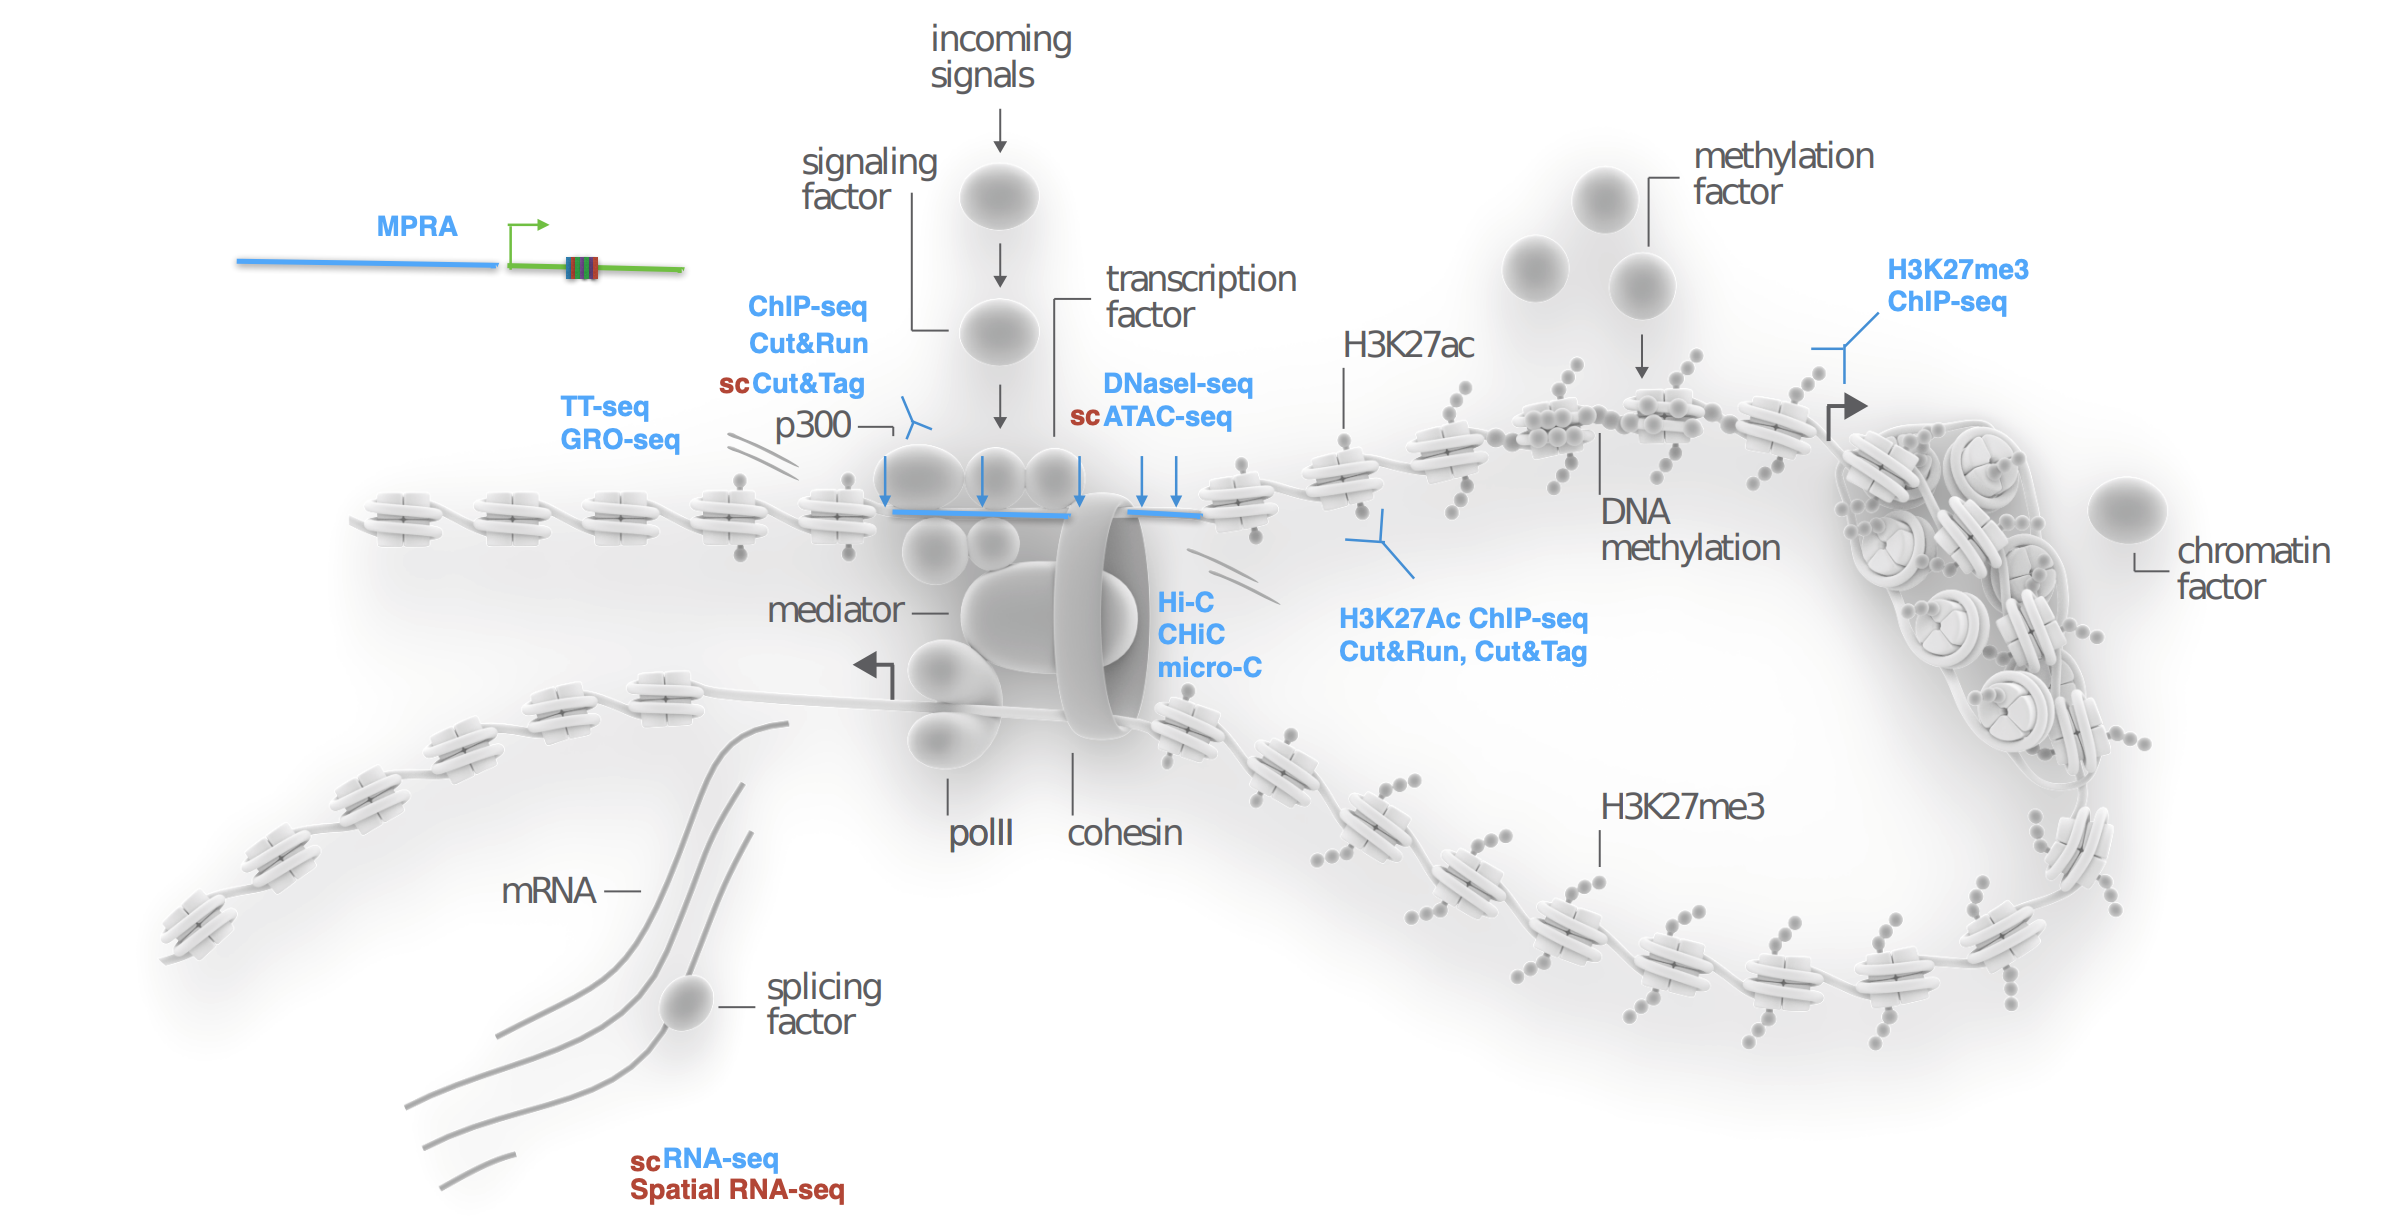

Gene regulation is a complex process that is regulated by a complex set of factors and sequences.

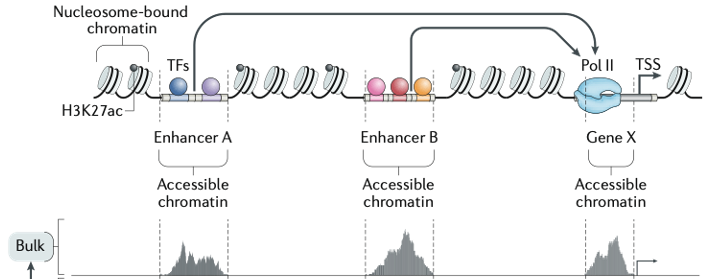

Minnoye et al., 2021

When transcription factors (TFs) and other factors bind the DNA, they displace nucleosomes and make the chromatin accessible. ATAC-seq (Assay for Transposase-Accessible Chromatin) uses the Tn5 transposase to profile and sequence the accessible regions of the chromatin.

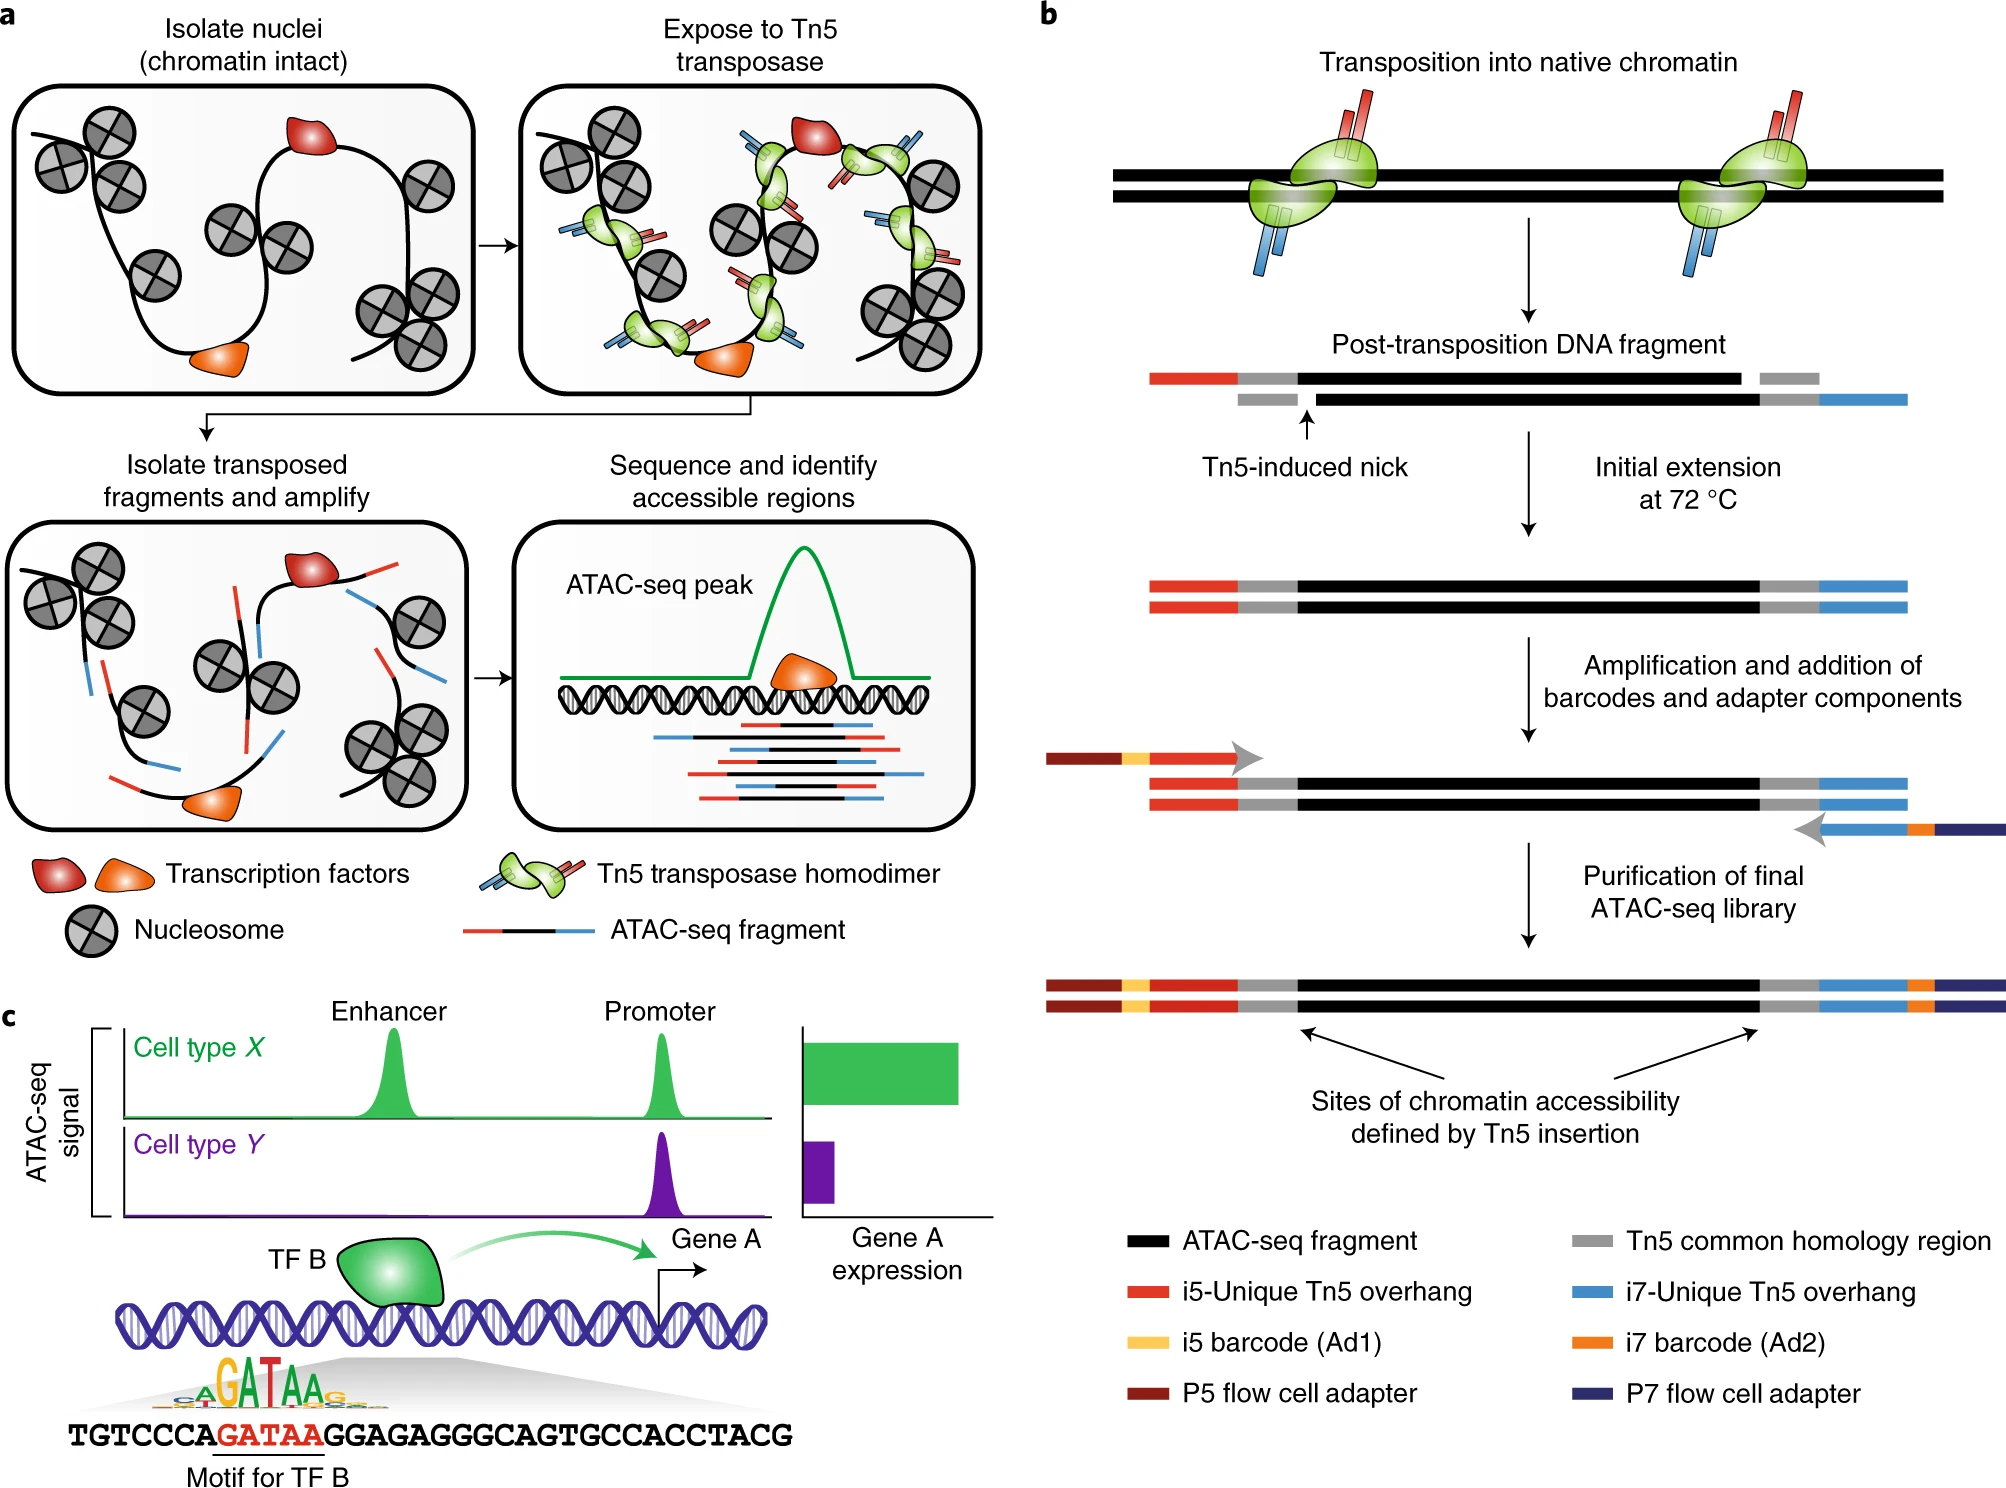

Grandi et al., 2022

Additional resources:

- [Harvard FAS Informatics - ATAC-seq Guidelines](https://github.com/harvardinformatics/ATAC-seq)
- [From reads to insight: a hitchhiker’s guide to ATAC-seq data analysis](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-1929-3)
- https://yiweiniu.github.io/blog/2019/03/ATAC-seq-data-analysis-from-FASTQ-to-peaks/
- https://vallierlab.wixsite.com/pipelines/atac-seq
- [ENCODE ATAC-seq pipeline](https://github.com/ENCODE-DCC/atac-seq-pipeline)

# Analysis

Here, we will analyse an ATAC-seq dataset, related to TP53 activation.

The following publicly available record at GEO https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE83780 contains MPRA (massively parallel reporter assay) and ATAC-Seq (assay for transpose-accessible chromatin) data sets related to TP53 activation.

However, the treatment (using doxorubicin to induce DNA damage) and the studied cells (fibroblasts) are different than the ones we used previously (MCF-7 breast cancer cells with nutlin-3a stimulation).

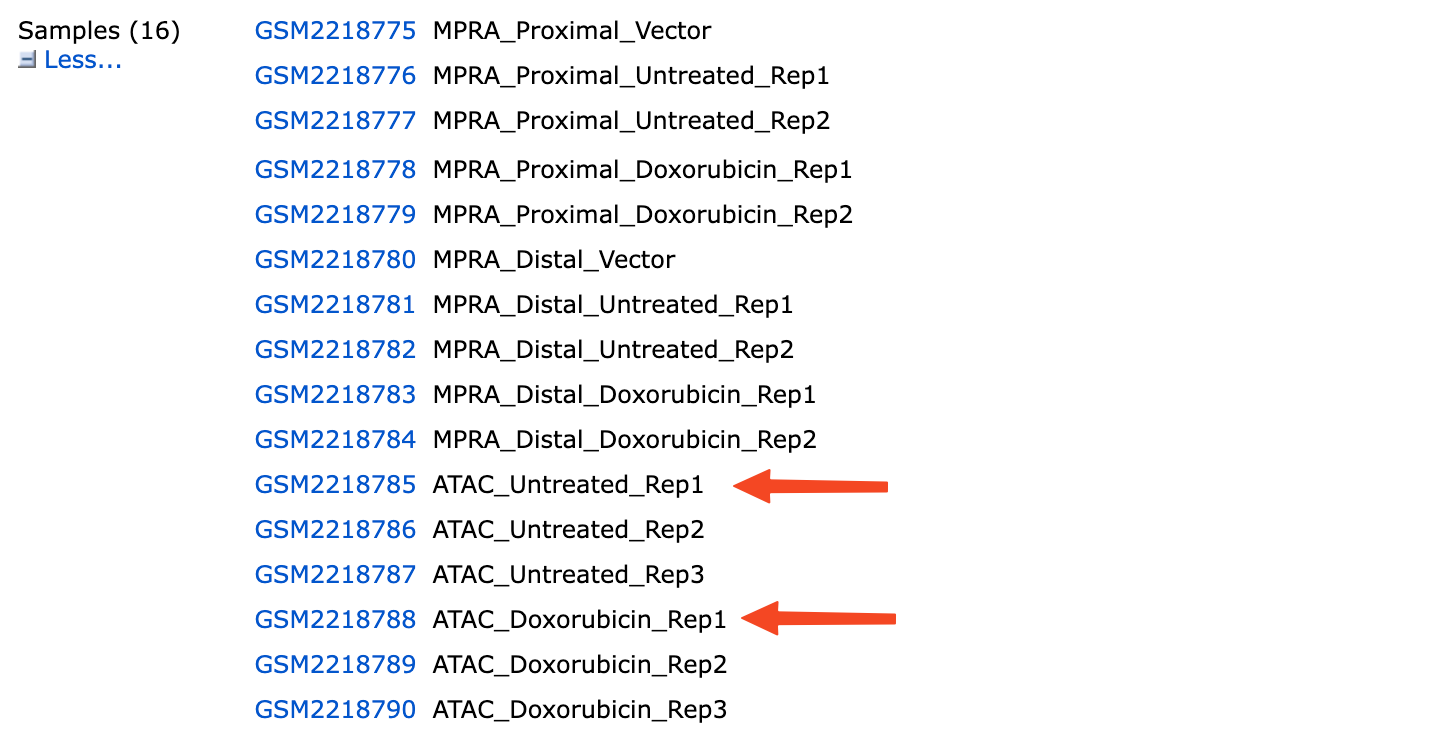
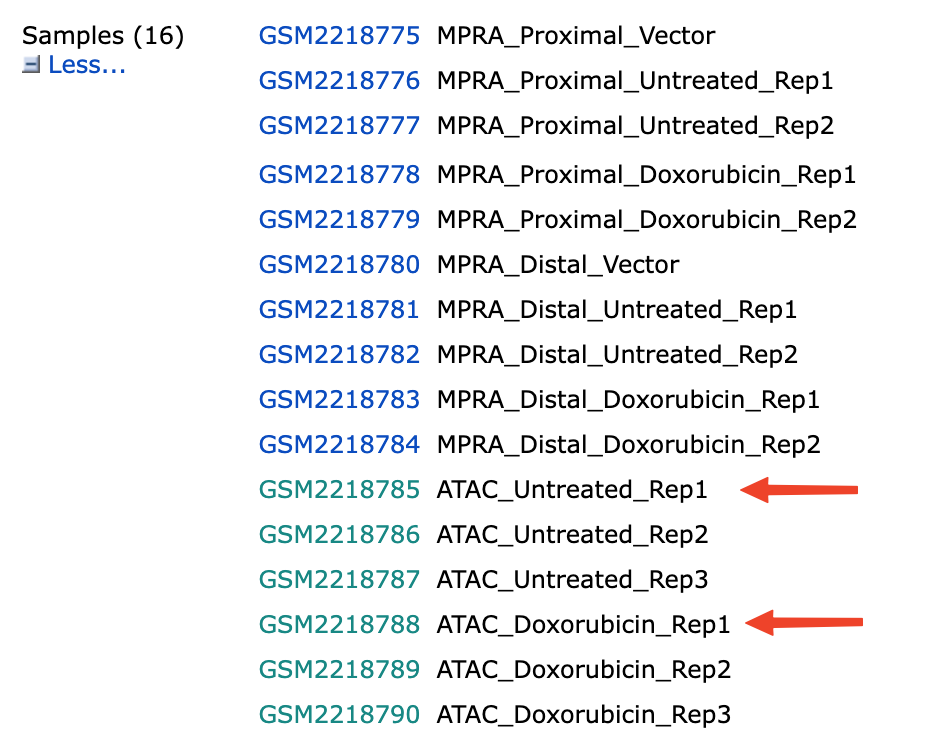

Let's create a directory for our analysis.

In [1]:
mkdir -p /data/user/$USER/atacseq/p53_doxorubicin
cd /data/user/$USER/atacseq/p53_doxorubicin

## Retrieval of fastq files

If you follow the links to two ATAC-seq datasets seen above, you can find the relevant SRR codes to retrieve the fastq files. Here are the codes:

SRR3722948 -> ATAC-seq (Untreated)

SRR3722951 -> ATAC-seq (Doxorubicin)

Using this code, you can download the full data but it will take it a long time, so we will skip this step for the illustration in class.

In [2]:
prefetch SRR3722948
fasterq-dump --threads 8 --progress SRR3722948

2025-10-22T20:56:59 prefetch.3.2.1: 1) Resolving 'SRR3722948'...
2025-10-22T20:57:00 prefetch.3.2.1: Current preference is set to retrieve SRA Normalized Format files with full base quality scores
2025-10-22T20:57:01 prefetch.3.2.1: 1) Downloading 'SRR3722948'...
2025-10-22T20:57:01 prefetch.3.2.1:  SRA Normalized Format file is being retrieved
2025-10-22T20:57:01 prefetch.3.2.1:  Downloading via HTTPS...
2025-10-22T21:00:31 prefetch.3.2.1:  HTTPS download succeed
2025-10-22T21:00:35 prefetch.3.2.1:  'SRR3722948' is valid: 2863451119 bytes were streamed from 2863442487
2025-10-22T21:00:35 prefetch.3.2.1: 1) 'SRR3722948' was downloaded successfully
join   :|-------------------------------------------------- 100%
concat :|-------------------------------------------------- 100%
spots read      : 22,050,601
reads read      : 44,101,202
reads written   : 44,101,202


In [3]:
prefetch SRR3722951
fasterq-dump --threads 8 --progress SRR3722951

2025-10-22T21:00:48 prefetch.3.2.1: 1) Resolving 'SRR3722951'...
2025-10-22T21:00:49 prefetch.3.2.1: Current preference is set to retrieve SRA Normalized Format files with full base quality scores
2025-10-22T21:00:50 prefetch.3.2.1: 1) Downloading 'SRR3722951'...
2025-10-22T21:00:50 prefetch.3.2.1:  SRA Normalized Format file is being retrieved
2025-10-22T21:00:50 prefetch.3.2.1:  Downloading via HTTPS...
2025-10-22T21:06:50 prefetch.3.2.1:  HTTPS download succeed
2025-10-22T21:06:57 prefetch.3.2.1:  'SRR3722951' is valid: 4366912253 bytes were streamed from 4366903925
2025-10-22T21:06:57 prefetch.3.2.1: 1) 'SRR3722951' was downloaded successfully
join   :|-------------------------------------------------- 100%
concat :|-------------------------------------------------- 100%
spots read      : 33,680,968
reads read      : 67,361,936
reads written   : 67,361,936


# Untreated sample analysis

## Check read quality

In [4]:
fastqc SRR3722948_1.fastq

null
Started analysis of SRR3722948_1.fastq
Approx 5% complete for SRR3722948_1.fastq
Approx 10% complete for SRR3722948_1.fastq
Approx 15% complete for SRR3722948_1.fastq
Approx 20% complete for SRR3722948_1.fastq
Approx 25% complete for SRR3722948_1.fastq
Approx 30% complete for SRR3722948_1.fastq
Approx 35% complete for SRR3722948_1.fastq
Approx 40% complete for SRR3722948_1.fastq
Approx 45% complete for SRR3722948_1.fastq
Approx 50% complete for SRR3722948_1.fastq
Approx 55% complete for SRR3722948_1.fastq
Approx 60% complete for SRR3722948_1.fastq
Approx 65% complete for SRR3722948_1.fastq
Approx 70% complete for SRR3722948_1.fastq
Approx 75% complete for SRR3722948_1.fastq
Approx 80% complete for SRR3722948_1.fastq
Approx 85% complete for SRR3722948_1.fastq
Approx 90% complete for SRR3722948_1.fastq
Approx 95% complete for SRR3722948_1.fastq
Analysis complete for SRR3722948_1.fastq


In [5]:
fastqc SRR3722948_2.fastq

null
Started analysis of SRR3722948_2.fastq
Approx 5% complete for SRR3722948_2.fastq
Approx 10% complete for SRR3722948_2.fastq
Approx 15% complete for SRR3722948_2.fastq
Approx 20% complete for SRR3722948_2.fastq
Approx 25% complete for SRR3722948_2.fastq
Approx 30% complete for SRR3722948_2.fastq
Approx 35% complete for SRR3722948_2.fastq
Approx 40% complete for SRR3722948_2.fastq
Approx 45% complete for SRR3722948_2.fastq
Approx 50% complete for SRR3722948_2.fastq
Approx 55% complete for SRR3722948_2.fastq
Approx 60% complete for SRR3722948_2.fastq
Approx 65% complete for SRR3722948_2.fastq
Approx 70% complete for SRR3722948_2.fastq
Approx 75% complete for SRR3722948_2.fastq
Approx 80% complete for SRR3722948_2.fastq
Approx 85% complete for SRR3722948_2.fastq
Approx 90% complete for SRR3722948_2.fastq
Approx 95% complete for SRR3722948_2.fastq
Analysis complete for SRR3722948_2.fastq


In [6]:
ls -lt | head

total 39533764
-rw-r--r-- 1 u0160030 domain users      644747 Oct 22 23:09 SRR3722948_2_fastqc.html
-rw-r--r-- 1 u0160030 domain users      467889 Oct 22 23:09 SRR3722948_2_fastqc.zip
-rw-r--r-- 1 u0160030 domain users      643478 Oct 22 23:08 SRR3722948_1_fastqc.html
-rw-r--r-- 1 u0160030 domain users      466425 Oct 22 23:08 SRR3722948_1_fastqc.zip
-rw-r--r-- 1 u0160030 domain users 12203442580 Oct 22 23:07 SRR3722951_2.fastq
-rw-r--r-- 1 u0160030 domain users 12203442580 Oct 22 23:07 SRR3722951_1.fastq
drwxr-xr-x 2 u0160030 domain users          36 Oct 22 23:06 SRR3722951
-rw-r--r-- 1 u0160030 domain users  7981792300 Oct 22 23:00 SRR3722948_2.fastq
-rw-r--r-- 1 u0160030 domain users  7981792300 Oct 22 23:00 SRR3722948_1.fastq


Check the number of reads we have (this is for all the reads)

In [7]:
wc -l SRR3722948_1.fastq | awk '{ print $1/4 }'

22050601


In [8]:
wc -l SRR3722948_2.fastq | awk '{ print $1/4 }'

22050601


Now we can open the report `fastqc.html` and check the quality of the data. For this data set, the sequencing quality scores are very good but we seem to have adapter sequences.

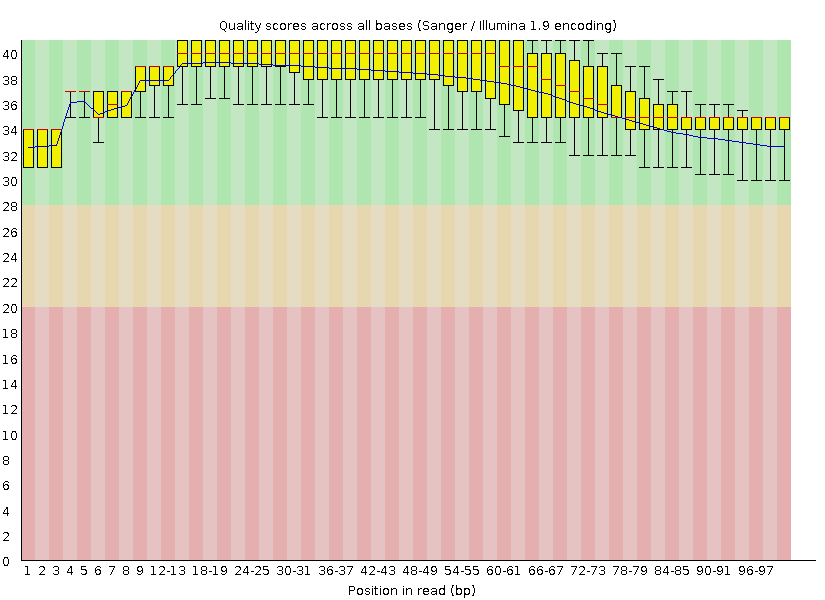

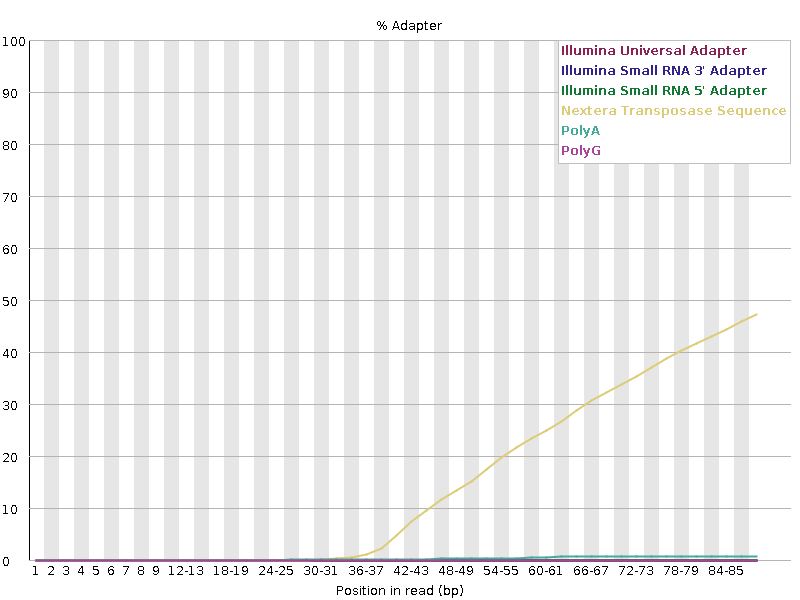

## Remove the adapters

You can use fastp, fastq-mcf, trimmomatic, cutadapt, etc. for this. We will illustrate [fastp](https://github.com/OpenGene/fastp) here which can automatically trim adapters, polyG tails, and do quality filtering.

In [9]:
fastp --help

usage: fastp [options] ... 
options:
  -i, --in1                            read1 input file name (string [=])
  -o, --out1                           read1 output file name (string [=])
  -I, --in2                            read2 input file name (string [=])
  -O, --out2                           read2 output file name (string [=])
      --unpaired1                      for PE input, if read1 passed QC but read2 not, it will be written to unpaired1. Default is to discard it. (string [=])
      --unpaired2                      for PE input, if read2 passed QC but read1 not, it will be written to unpaired2. If --unpaired2 is same as --unpaired1 (default mode), both unpaired reads will be written to this same file. (string [=])
      --overlapped_out                 for each read pair, output the overlapped region if it has no any mismatched base. (string [=])
      --failed_out                     specify the file to store reads that cannot pass the filters. (string [=])
  -m, --merge  

In [10]:
# This automatically detects adapters but you can also provide a FASTA file of adapter sequences 
fastp \
--in1 SRR3722948_1.fastq --in2 SRR3722948_2.fastq \
--out1 SRR3722948_1_clean.fastq --out2 SRR3722948_2_clean.fastq \
--length_required 25 # reads shorter than this length will be discarded

Read1 before filtering:
total reads: 22050601
total bases: 2205060100
Q20 bases: 2170505900(98.433%)
Q30 bases: 2108377481(95.6154%)
Q40 bases: 763692935(34.6337%)

Read2 before filtering:
total reads: 22050601
total bases: 2205060100
Q20 bases: 2147184045(97.3753%)
Q30 bases: 2079581631(94.3095%)
Q40 bases: 760622742(34.4944%)

Read1 after filtering:
total reads: 21539267
total bases: 1724388987
Q20 bases: 1712257551(99.2965%)
Q30 bases: 1674164072(97.0874%)
Q40 bases: 681145945(39.5007%)

Read2 after filtering:
total reads: 21539267
total bases: 1724388987
Q20 bases: 1708925119(99.1032%)
Q30 bases: 1666043698(96.6165%)
Q40 bases: 676068322(39.2063%)

Filtering result:
reads passed filter: 43078534
reads failed due to low quality: 1014960
reads failed due to too many N: 7708
reads failed due to too short: 0
reads with adapter trimmed: 23788012
bases trimmed due to adapters: 863208944

Duplication rate: 35.0858%

Insert size peak (evaluated by paired-end reads): 40

JSON report: fastp.

### Let's check the QC again

In [11]:
fastqc SRR3722948_1_clean.fastq

null
Started analysis of SRR3722948_1_clean.fastq
Approx 5% complete for SRR3722948_1_clean.fastq
Approx 10% complete for SRR3722948_1_clean.fastq
Approx 15% complete for SRR3722948_1_clean.fastq
Approx 20% complete for SRR3722948_1_clean.fastq
Approx 25% complete for SRR3722948_1_clean.fastq
Approx 30% complete for SRR3722948_1_clean.fastq
Approx 35% complete for SRR3722948_1_clean.fastq
Approx 40% complete for SRR3722948_1_clean.fastq
Approx 45% complete for SRR3722948_1_clean.fastq
Approx 50% complete for SRR3722948_1_clean.fastq
Approx 55% complete for SRR3722948_1_clean.fastq
Approx 60% complete for SRR3722948_1_clean.fastq
Approx 65% complete for SRR3722948_1_clean.fastq
Approx 70% complete for SRR3722948_1_clean.fastq
Approx 75% complete for SRR3722948_1_clean.fastq
Approx 80% complete for SRR3722948_1_clean.fastq
Approx 85% complete for SRR3722948_1_clean.fastq
Approx 90% complete for SRR3722948_1_clean.fastq
Approx 95% complete for SRR3722948_1_clean.fastq
Analysis complete fo

In [12]:
fastqc SRR3722948_2_clean.fastq

null
Started analysis of SRR3722948_2_clean.fastq
Approx 5% complete for SRR3722948_2_clean.fastq
Approx 10% complete for SRR3722948_2_clean.fastq
Approx 15% complete for SRR3722948_2_clean.fastq
Approx 20% complete for SRR3722948_2_clean.fastq
Approx 25% complete for SRR3722948_2_clean.fastq
Approx 30% complete for SRR3722948_2_clean.fastq
Approx 35% complete for SRR3722948_2_clean.fastq
Approx 40% complete for SRR3722948_2_clean.fastq
Approx 45% complete for SRR3722948_2_clean.fastq
Approx 50% complete for SRR3722948_2_clean.fastq
Approx 55% complete for SRR3722948_2_clean.fastq
Approx 60% complete for SRR3722948_2_clean.fastq
Approx 65% complete for SRR3722948_2_clean.fastq
Approx 70% complete for SRR3722948_2_clean.fastq
Approx 75% complete for SRR3722948_2_clean.fastq
Approx 80% complete for SRR3722948_2_clean.fastq
Approx 85% complete for SRR3722948_2_clean.fastq
Approx 90% complete for SRR3722948_2_clean.fastq
Approx 95% complete for SRR3722948_2_clean.fastq
Analysis complete fo

Ok, looks good now!

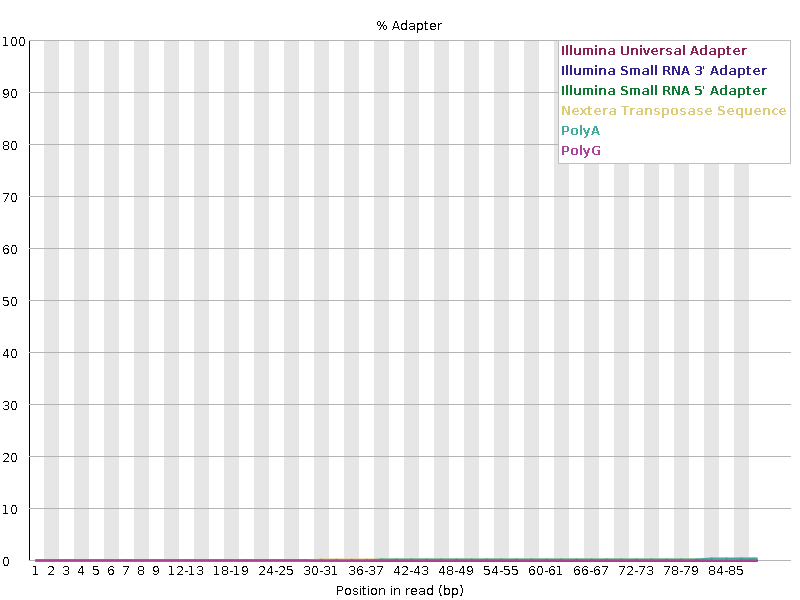
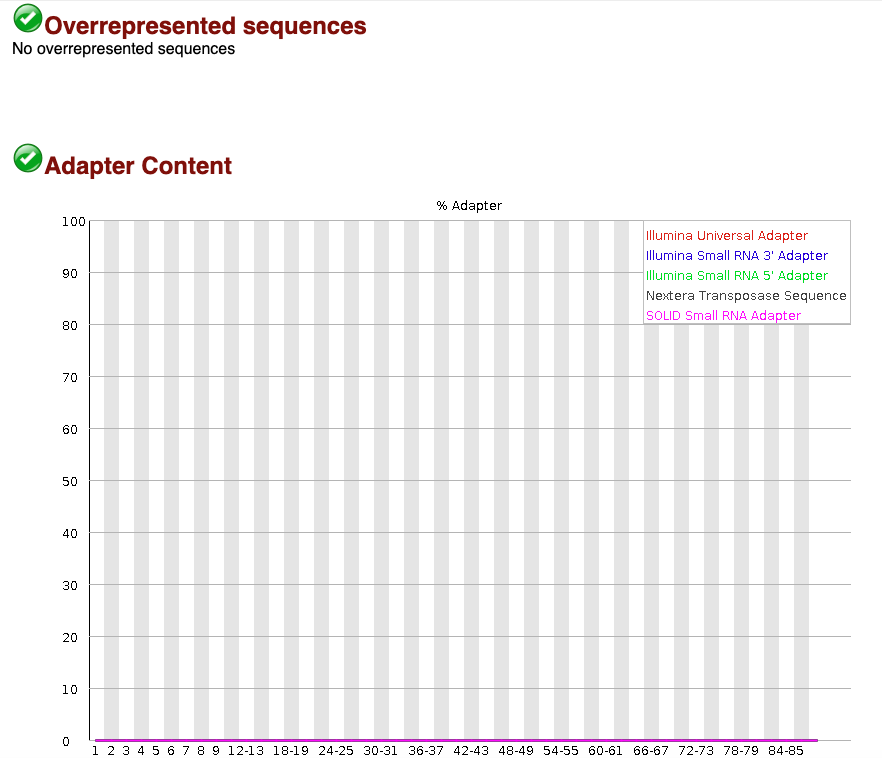

Check the number of reads we have after filtering

In [13]:
wc -l SRR3722948_1_clean.fastq | awk '{ print $1/4 }'

21539267


In [14]:
wc -l SRR3722948_2_clean.fastq | awk '{ print $1/4 }'

21539267


## Alignment of reads

After retrieving and cleaning our fastq files, we can align them to our genome. This step is computationally expensive, so for the illustration in class, we have already done all these steps and will demonstrate how it's done genome-wide.

To align the reads to the genome, we will use bowtie2. As reference genome, you can use the whole genome bowtie index at this location */data/teachers/data/genomes/hg19/bowtie2*. Alternatively, you can use bwa-mem to align reads. Here we will align to the hg19 human assembly. 

In [15]:
bowtie2 -p 16 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 -1 SRR3722948_1_clean.fastq -2 SRR3722948_2_clean.fastq -S ATAC_untreated.sam

21539267 reads; of these:
  21539267 (100.00%) were paired; of these:
    852839 (3.96%) aligned concordantly 0 times
    15718770 (72.98%) aligned concordantly exactly 1 time
    4967658 (23.06%) aligned concordantly >1 times
    ----
    852839 pairs aligned concordantly 0 times; of these:
      131894 (15.47%) aligned discordantly 1 time
    ----
    720945 pairs aligned 0 times concordantly or discordantly; of these:
      1441890 mates make up the pairs; of these:
        1300553 (90.20%) aligned 0 times
        52769 (3.66%) aligned exactly 1 time
        88568 (6.14%) aligned >1 times
96.98% overall alignment rate


Check a couple of lines in the SAM file

In [16]:
head -500 ATAC_untreated.sam | tail -5

SRR3722948.244	147	chr6	139365992	42	99M	=	139365992	-99	TTTCTAGATTAGCAATTCTAGTAGAGGGAGCATTTATTATAATATCTAATTATGAATTCCAAGAAGGAAATTCTGATTGCTTCCACTGCAGTATAAACC	EEEEEFDFDFFHHFHHEGGIIIJJJJJJIIIHCGGGHJJJJJJIIIJJIHIJIIHHHFHHEHIJHFIJJJJJIJIIIJJIIGHGFGBGHGHFDDDD@@@	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:99	YS:i:0	YT:Z:CP
SRR3722948.245	83	chr11	117522348	38	49M	=	117522348	-49	ACCCAGGAGGTGGAGCTTGCAGTGAGCCGAGATCTTGCCAGCGTACTCC	HJJJJJJIJHIJJJJJJIIJJJJJJJJJIJIJJJJIHHHHHDA=DFBBB	AS:i:0	XS:i:-26	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:49	YS:i:0	YT:Z:CP
SRR3722948.245	163	chr11	117522348	38	49M	=	117522348	49	ACCCAGGAGGTGGAGCTTGCAGTGAGCCGAGATCTTGCCAGCGTACTCC	BBBFFFFFHHCFHIJJJJJJJJJJJJJJJJJJJJJJJJJJJJJFHIIJJ	AS:i:0	XS:i:-27	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:49	YS:i:0	YT:Z:CP
SRR3722948.246	83	chrM	3442	24	53M	=	3442	-53	ACTACAGCCTTTCGCTGACGCCATAAAACTCTTCACCAAAGAGCCCCTAAAAC	=EC@IIGAFAD<HFF<F@JIHEGGGHE?IIEHFA<HIHIGFHDHDDD?DD@?@	AS:i:-10	XN:i:0	XM:i:2	XO:i:0	XG:i:0	NM:i:2	MD:Z:6A2C43	YS:i:-

Convert the SAM file to BAM format (binary)

In [17]:
samtools view -@ 8 -S -b ATAC_untreated.sam > ATAC_untreated.bam

We can delete the SAM file now to save space

In [18]:
rm ATAC_untreated.sam

How many reads are in the BAM file?
These are paired so should be 21539267 * 2 = 43078534

In [19]:
samtools view -c ATAC_untreated.bam

43078534


How many of these reads are mapped?


In [20]:
# Get correct flag settings for samtools view (second column)
# Here you can decode SAM Flags http://broadinstitute.github.io/picard/explain-flags.html
samtools flags UNMAP,SECONDARY

0x104	260	UNMAP,SECONDARY


In [21]:
# Number of mapped reads
samtools view -@ 4 -c -F 260 ATAC_untreated.bam

41777981


Now we are going to create the .bai index so we can use the BAM file in IGV

In [22]:
samtools sort -@ 4 -O bam -o ATAC_untreated.sorted.bam ATAC_untreated.bam

[bam_sort_core] merging from 3 files and 4 in-memory blocks...


In [23]:
samtools index -@ 4 ATAC_untreated.sorted.bam

## Checking the BAM file in IGV

Now you can download the bam and the index (bam.bai) file to visualize your results in IGV. Here's an example of how it should look near the BBC3 gene (they are colored by read strand; remember the MACS peak calling trick!) :

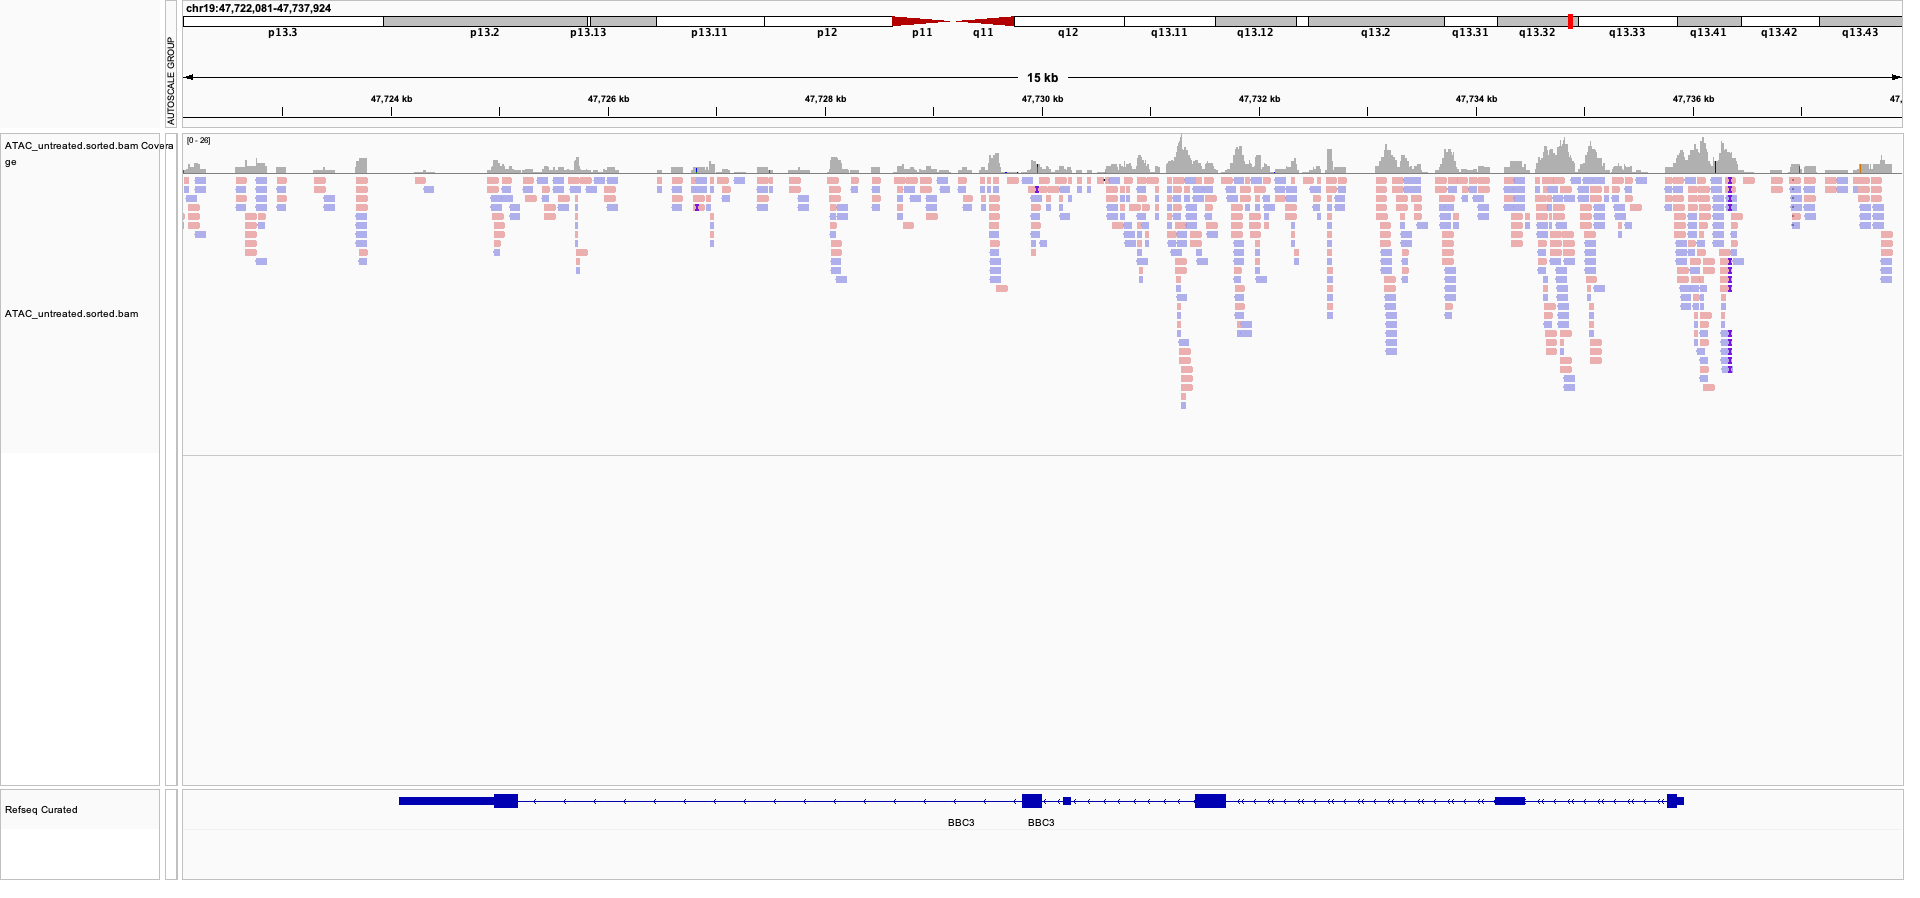

# Doxorubicin treated sample analysis

## Check read quality

In [27]:
fastqc SRR3722951_1.fastq

null
Started analysis of SRR3722951_1.fastq
Approx 5% complete for SRR3722951_1.fastq
Approx 10% complete for SRR3722951_1.fastq
Approx 15% complete for SRR3722951_1.fastq
Approx 20% complete for SRR3722951_1.fastq
Approx 25% complete for SRR3722951_1.fastq
Approx 30% complete for SRR3722951_1.fastq
Approx 35% complete for SRR3722951_1.fastq
Approx 40% complete for SRR3722951_1.fastq
Approx 45% complete for SRR3722951_1.fastq
Approx 50% complete for SRR3722951_1.fastq
Approx 55% complete for SRR3722951_1.fastq
Approx 60% complete for SRR3722951_1.fastq
Approx 65% complete for SRR3722951_1.fastq
Approx 70% complete for SRR3722951_1.fastq
Approx 75% complete for SRR3722951_1.fastq
Approx 80% complete for SRR3722951_1.fastq
Approx 85% complete for SRR3722951_1.fastq
Approx 90% complete for SRR3722951_1.fastq
Approx 95% complete for SRR3722951_1.fastq
Analysis complete for SRR3722951_1.fastq


In [28]:
fastqc SRR3722951_2.fastq

null
Started analysis of SRR3722951_2.fastq
Approx 5% complete for SRR3722951_2.fastq
Approx 10% complete for SRR3722951_2.fastq
Approx 15% complete for SRR3722951_2.fastq
Approx 20% complete for SRR3722951_2.fastq
Approx 25% complete for SRR3722951_2.fastq
Approx 30% complete for SRR3722951_2.fastq
Approx 35% complete for SRR3722951_2.fastq
Approx 40% complete for SRR3722951_2.fastq
Approx 45% complete for SRR3722951_2.fastq
Approx 50% complete for SRR3722951_2.fastq
Approx 55% complete for SRR3722951_2.fastq
Approx 60% complete for SRR3722951_2.fastq
Approx 65% complete for SRR3722951_2.fastq
Approx 70% complete for SRR3722951_2.fastq
Approx 75% complete for SRR3722951_2.fastq
Approx 80% complete for SRR3722951_2.fastq
Approx 85% complete for SRR3722951_2.fastq
Approx 90% complete for SRR3722951_2.fastq
Approx 95% complete for SRR3722951_2.fastq
Analysis complete for SRR3722951_2.fastq


In [29]:
ls -lt | head

total 59664972
-rw-r--r-- 1 u0160030 domain users      640743 Oct 22 23:25 SRR3722951_2_fastqc.html
-rw-r--r-- 1 u0160030 domain users      463242 Oct 22 23:25 SRR3722951_2_fastqc.zip
-rw-r--r-- 1 u0160030 domain users      643989 Oct 22 23:23 SRR3722951_1_fastqc.html
-rw-r--r-- 1 u0160030 domain users      464123 Oct 22 23:23 SRR3722951_1_fastqc.zip
-rw-r--r-- 1 u0160030 domain users   102521076 Oct 22 23:21 ATAC_untreated_chr19_end1.fastq
-rw-r--r-- 1 u0160030 domain users   102521076 Oct 22 23:21 ATAC_untreated_chr19_end2.fastq
-rw-r--r-- 1 u0160030 domain users    86740695 Oct 22 23:21 ATAC_untreated_chr19_qsort.bam
-rw-r--r-- 1 u0160030 domain users   405859082 Oct 22 23:21 ATAC_untreated_chr19.fastq
-rw-r--r-- 1 u0160030 domain users    71240116 Oct 22 23:21 ATAC_untreated_chr19.bam


Check the number of reads we have (this is for all the reads)

In [30]:
wc -l SRR3722951_1.fastq | awk '{ print $1/4 }'

33680968


In [31]:
wc -l SRR3722951_2.fastq | awk '{ print $1/4 }'

33680968


Again, we can now open the report `fastqc.html` and check the quality of the data. We observe a similar finding, the sequencing quality scores are very good but we seem to have adapter sequences.

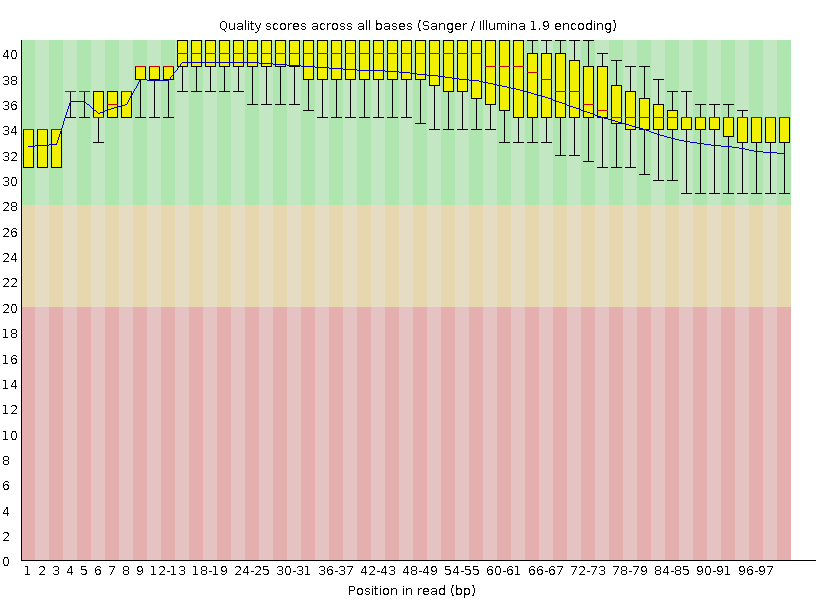

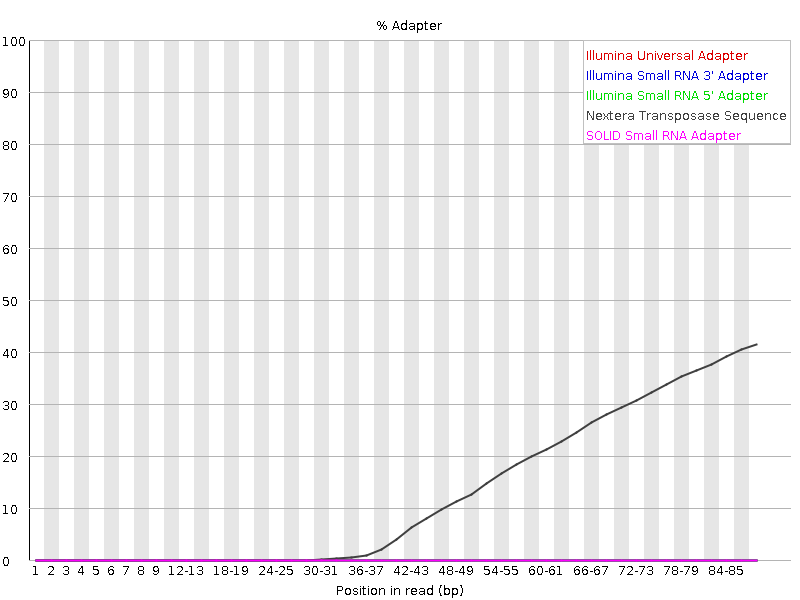

## Remove the adapters

We will use [fastp](https://github.com/OpenGene/fastp) again here

In [32]:
# Trim adapters
fastp \
--in1 SRR3722951_1.fastq --in2 SRR3722951_2.fastq \
--out1 SRR3722951_1_clean.fastq --out2 SRR3722951_2_clean.fastq \
--length_required 25 # reads shorter than this length will be discarded

Read1 before filtering:
total reads: 33680968
total bases: 3368096800
Q20 bases: 3300763501(98.0009%)
Q30 bases: 3203669083(95.1181%)
Q40 bases: 1162791518(34.5237%)

Read2 before filtering:
total reads: 33680968
total bases: 3368096800
Q20 bases: 3230798718(95.9236%)
Q30 bases: 3115411156(92.4977%)
Q40 bases: 1099701145(32.6505%)

Read1 after filtering:
total reads: 32440435
total bases: 2671182166
Q20 bases: 2653539890(99.3395%)
Q30 bases: 2596850080(97.2173%)
Q40 bases: 1049916854(39.3053%)

Read2 after filtering:
total reads: 32440435
total bases: 2671182166
Q20 bases: 2641897501(98.9037%)
Q30 bases: 2562933685(95.9475%)
Q40 bases: 992904320(37.171%)

Filtering result:
reads passed filter: 64880870
reads failed due to low quality: 2468600
reads failed due to too many N: 12466
reads failed due to too short: 0
reads with adapter trimmed: 32490028
bases trimmed due to adapters: 1152181764

Duplication rate: 32.2928%

Insert size peak (evaluated by paired-end reads): 40

JSON report: f

### Let's check the QC again

In [33]:
fastqc SRR3722951_1_clean.fastq

null
Started analysis of SRR3722951_1_clean.fastq
Approx 5% complete for SRR3722951_1_clean.fastq
Approx 10% complete for SRR3722951_1_clean.fastq
Approx 15% complete for SRR3722951_1_clean.fastq
Approx 20% complete for SRR3722951_1_clean.fastq
Approx 25% complete for SRR3722951_1_clean.fastq
Approx 30% complete for SRR3722951_1_clean.fastq
Approx 35% complete for SRR3722951_1_clean.fastq
Approx 40% complete for SRR3722951_1_clean.fastq
Approx 45% complete for SRR3722951_1_clean.fastq
Approx 50% complete for SRR3722951_1_clean.fastq
Approx 55% complete for SRR3722951_1_clean.fastq
Approx 60% complete for SRR3722951_1_clean.fastq
Approx 65% complete for SRR3722951_1_clean.fastq
Approx 70% complete for SRR3722951_1_clean.fastq
Approx 75% complete for SRR3722951_1_clean.fastq
Approx 80% complete for SRR3722951_1_clean.fastq
Approx 85% complete for SRR3722951_1_clean.fastq
Approx 90% complete for SRR3722951_1_clean.fastq
Approx 95% complete for SRR3722951_1_clean.fastq
Analysis complete fo

In [34]:
fastqc SRR3722951_2_clean.fastq

null
Started analysis of SRR3722951_2_clean.fastq
Approx 5% complete for SRR3722951_2_clean.fastq
Approx 10% complete for SRR3722951_2_clean.fastq
Approx 15% complete for SRR3722951_2_clean.fastq
Approx 20% complete for SRR3722951_2_clean.fastq
Approx 25% complete for SRR3722951_2_clean.fastq
Approx 30% complete for SRR3722951_2_clean.fastq
Approx 35% complete for SRR3722951_2_clean.fastq
Approx 40% complete for SRR3722951_2_clean.fastq
Approx 45% complete for SRR3722951_2_clean.fastq
Approx 50% complete for SRR3722951_2_clean.fastq
Approx 55% complete for SRR3722951_2_clean.fastq
Approx 60% complete for SRR3722951_2_clean.fastq
Approx 65% complete for SRR3722951_2_clean.fastq
Approx 70% complete for SRR3722951_2_clean.fastq
Approx 75% complete for SRR3722951_2_clean.fastq
Approx 80% complete for SRR3722951_2_clean.fastq
Approx 85% complete for SRR3722951_2_clean.fastq
Approx 90% complete for SRR3722951_2_clean.fastq
Approx 95% complete for SRR3722951_2_clean.fastq
Analysis complete fo

Looks good!

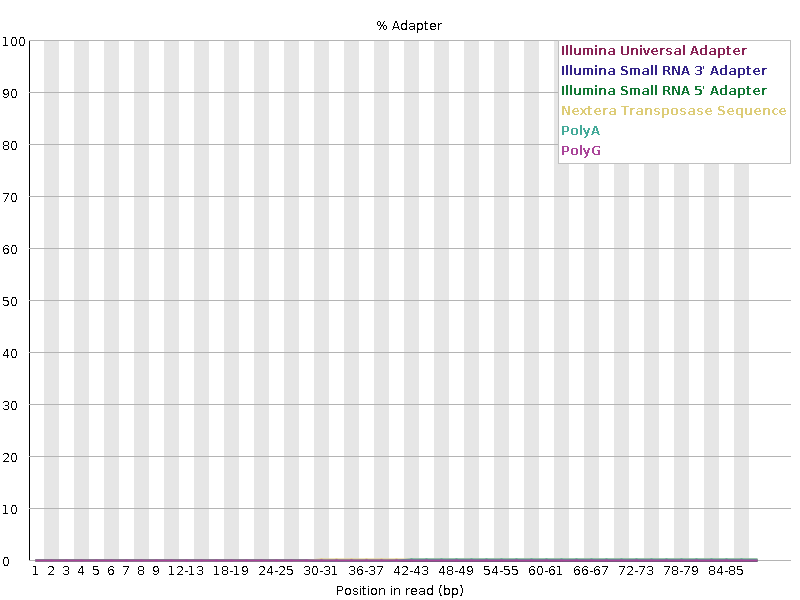
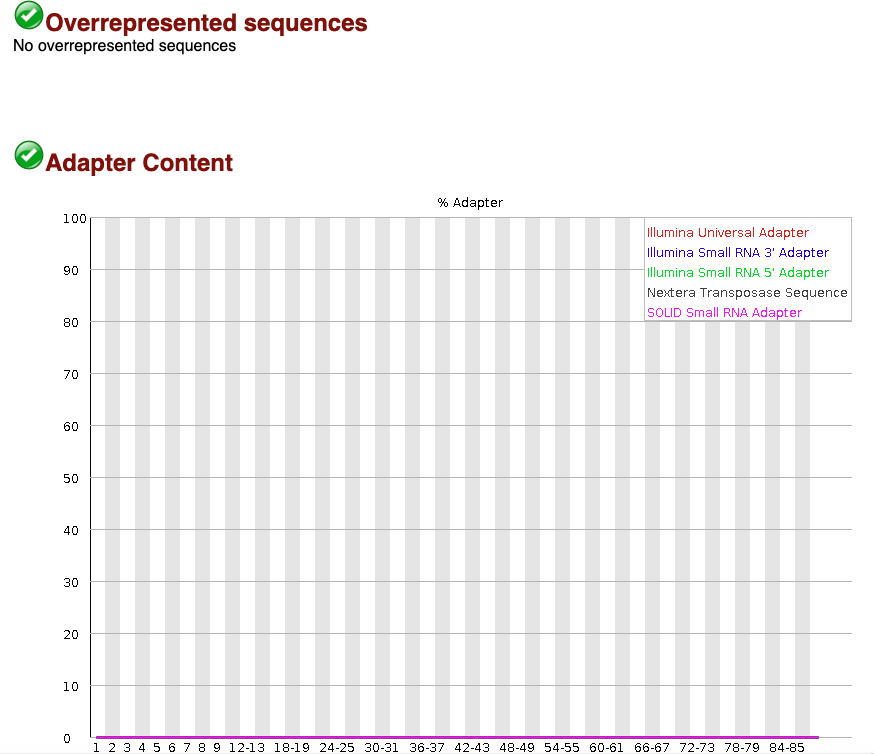

Check the number of reads we have after filtering

In [35]:
wc -l SRR3722951_1_clean.fastq | awk '{ print $1/4 }'

32440435


In [36]:
wc -l SRR3722951_2_clean.fastq | awk '{ print $1/4 }'

32440435


## Alignment of reads

After retrieving and cleaning our fastq files, we can align them to our genome. This step is computationally expensive, so for the illustration in class, we have already done all these steps and will demonstrate how it's done genome-wide.

To align the reads to the genome, we will use bowtie2. As reference genome, you can use the whole genome bowtie index at this location */data/teachers/data/genomes/hg19/bowtie2*. Alternatively, you can use bwa-mem to align reads. Here we will align to the hg19 human assembly. 

In [37]:
bowtie2 -p 16 -x /data/teachers/data/genomes/hg19/bowtie2/hg19 -1 SRR3722951_1_clean.fastq -2 SRR3722951_2_clean.fastq -S ATAC_doxorubicin.sam

32440435 reads; of these:
  32440435 (100.00%) were paired; of these:
    1237280 (3.81%) aligned concordantly 0 times
    24162257 (74.48%) aligned concordantly exactly 1 time
    7040898 (21.70%) aligned concordantly >1 times
    ----
    1237280 pairs aligned concordantly 0 times; of these:
      201755 (16.31%) aligned discordantly 1 time
    ----
    1035525 pairs aligned 0 times concordantly or discordantly; of these:
      2071050 mates make up the pairs; of these:
        1864666 (90.03%) aligned 0 times
        89933 (4.34%) aligned exactly 1 time
        116451 (5.62%) aligned >1 times
97.13% overall alignment rate


Check a couple of lines in the SAM file

In [38]:
head -500 ATAC_doxorubicin.sam | tail -5

SRR3722951.278	163	chr5	68117074	42	70M	=	68117074	70	TTGTACACAAGCAACAGTATTATTTTCAGAGTGATAGAACACTTTGCCCAGACAGCTGAGGCCACAATTG	BBCDDFFFHHHHGJJJIHIJJJJJJJIJIHJCDGIJJJJIIJJJJJJJJJJJJJIIHIHGFIJJGIGIJI	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:70	YS:i:0	YT:Z:CP
SRR3722951.279	83	chr3	137864606	42	100M	=	137864355	-351	TCTGAAAATGCTACATGCTTTATGTTTCCAACTATATGACATTCTGGAAAATGCAAAACTATGGAGCTAGTAAAAAGATCAGTGGCTACCAGGGTTACAA	EEEEEEFFFFFFFHHHHHHIJJJJIJJIJIHHFB=88JIJJJJJJJJJJJJJJJJIHGJJJJJJJJJJJJJJJJJJJJJJJJJJJJJHHHHHFFDFFCCC	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:100	YS:i:0	YT:Z:CP
SRR3722951.279	163	chr3	137864355	42	100M	=	137864606	351	TCACAGTCCTGCGTATTTACCCAAGGGTGCTAAAAGCTTGTGTCCACACAAAAACCTGCACATGGATATTTATAGCAGTTTTATTCACAACTGCCAAAAC	CCCFFFFFHHHHHIJJJJJJJJJJJJJHHIJJJJJJJJJJJJIJJJJJJJJJJJJJJJJJJJHHHHHHFFFFFFFFEEEEEEDDDEEDDDDDDCDDDDDD	AS:i:0	XN:i:0	XM:i:0	XO:i:0	XG:i:0	NM:i:0	MD:Z:100	YS:i:0	YT:Z:CP
SRR3722951.280	83	chr2	221749465	42	100M	=	221749231	-334	AATAACTCTACTTTTTGAAATCAAAATAT

Convert the SAM file to BAM format (binary)

In [39]:
samtools view -@ 8 -S -b ATAC_doxorubicin.sam > ATAC_doxorubicin.bam

We can delete the SAM file now to save space

In [40]:
rm ATAC_doxorubicin.sam

How many reads are in the BAM file?
These are paired so should be 32440435 * 2 = 64880870

In [41]:
samtools view -c ATAC_doxorubicin.bam

64880870


How many of these reads are mapped?


In [42]:
# Number of mapped reads
samtools view -@ 4 -c -F 260 ATAC_doxorubicin.bam

63016204


Now we are going to create the .bai index so we can use the BAM file in IGV

In [43]:
samtools sort -@ 4 -O bam -o ATAC_doxorubicin.sorted.bam ATAC_doxorubicin.bam

[bam_sort_core] merging from 5 files and 4 in-memory blocks...


In [44]:
samtools index -@ 4 ATAC_doxorubicin.sorted.bam

## Checking the BAM file in IGV

Now you can download the bam and the index (bam.bai) file to visualize your results in IGV. Here's an example:

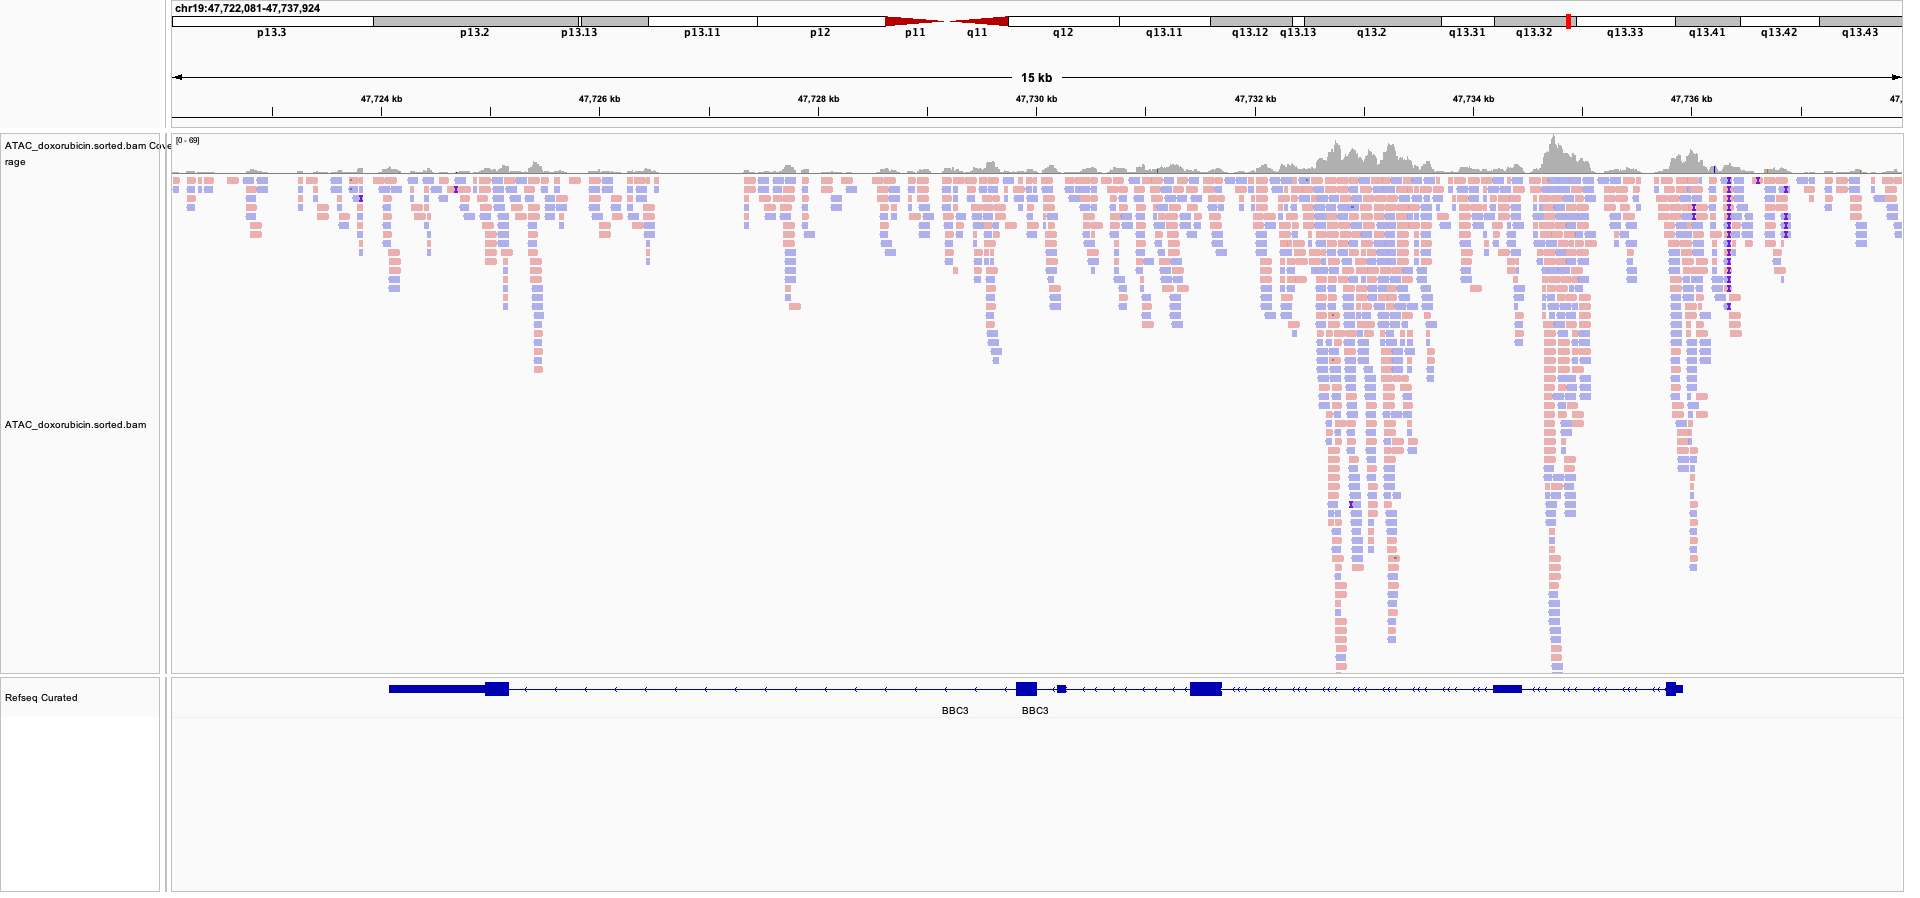

# Filter BAM files

In [48]:
samtools view -b -h -f 3 -F 3340 -q 30 ATAC_untreated.sorted.bam | samtools sort -@ 8 -o ATAC_untreated_sorted_filtered.bam
samtools index ATAC_untreated_sorted_filtered.bam

[bam_sort_core] merging from 1 files and 8 in-memory blocks...


In [49]:
samtools view -b -h -f 3 -F 3340 -q 30 ATAC_doxorubicin.sorted.bam | samtools sort -@ 8 -o ATAC_doxorubicin_sorted_filtered.bam
samtools index ATAC_doxorubicin_sorted_filtered.bam

[bam_sort_core] merging from 2 files and 8 in-memory blocks...


Now that we have the files for both conditions, we can load them together and try to see if we can find differences. Don't forget that there are some caveats here, first if you don't group autoscale your tracks, the y axis for each track will be different (you can do the scaling by selecting both tracks, right click, group autoscale). If you do that keep in mind that in the case of data that is not normalized to read depth, your peaks will be biased. You can try autoscaling in that case (not group autoscale). Try all of it out now and notice how the same data looks in different cases.

BBC3 gene

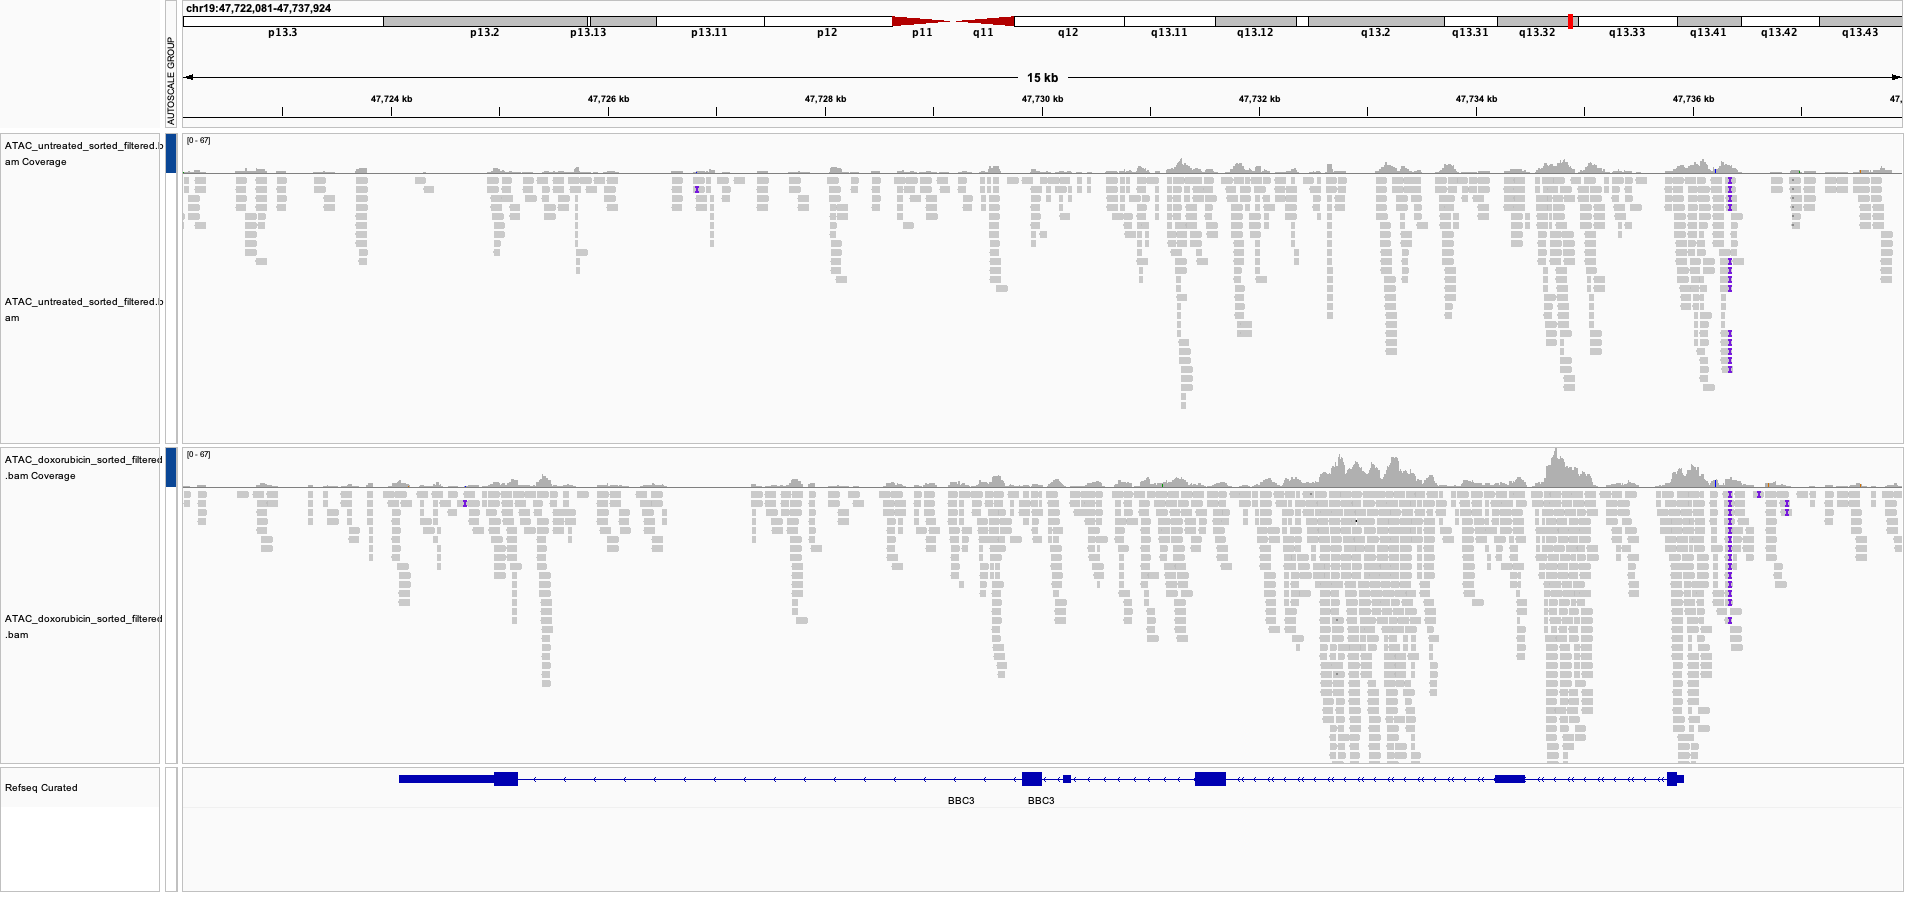

CDKN1A gene

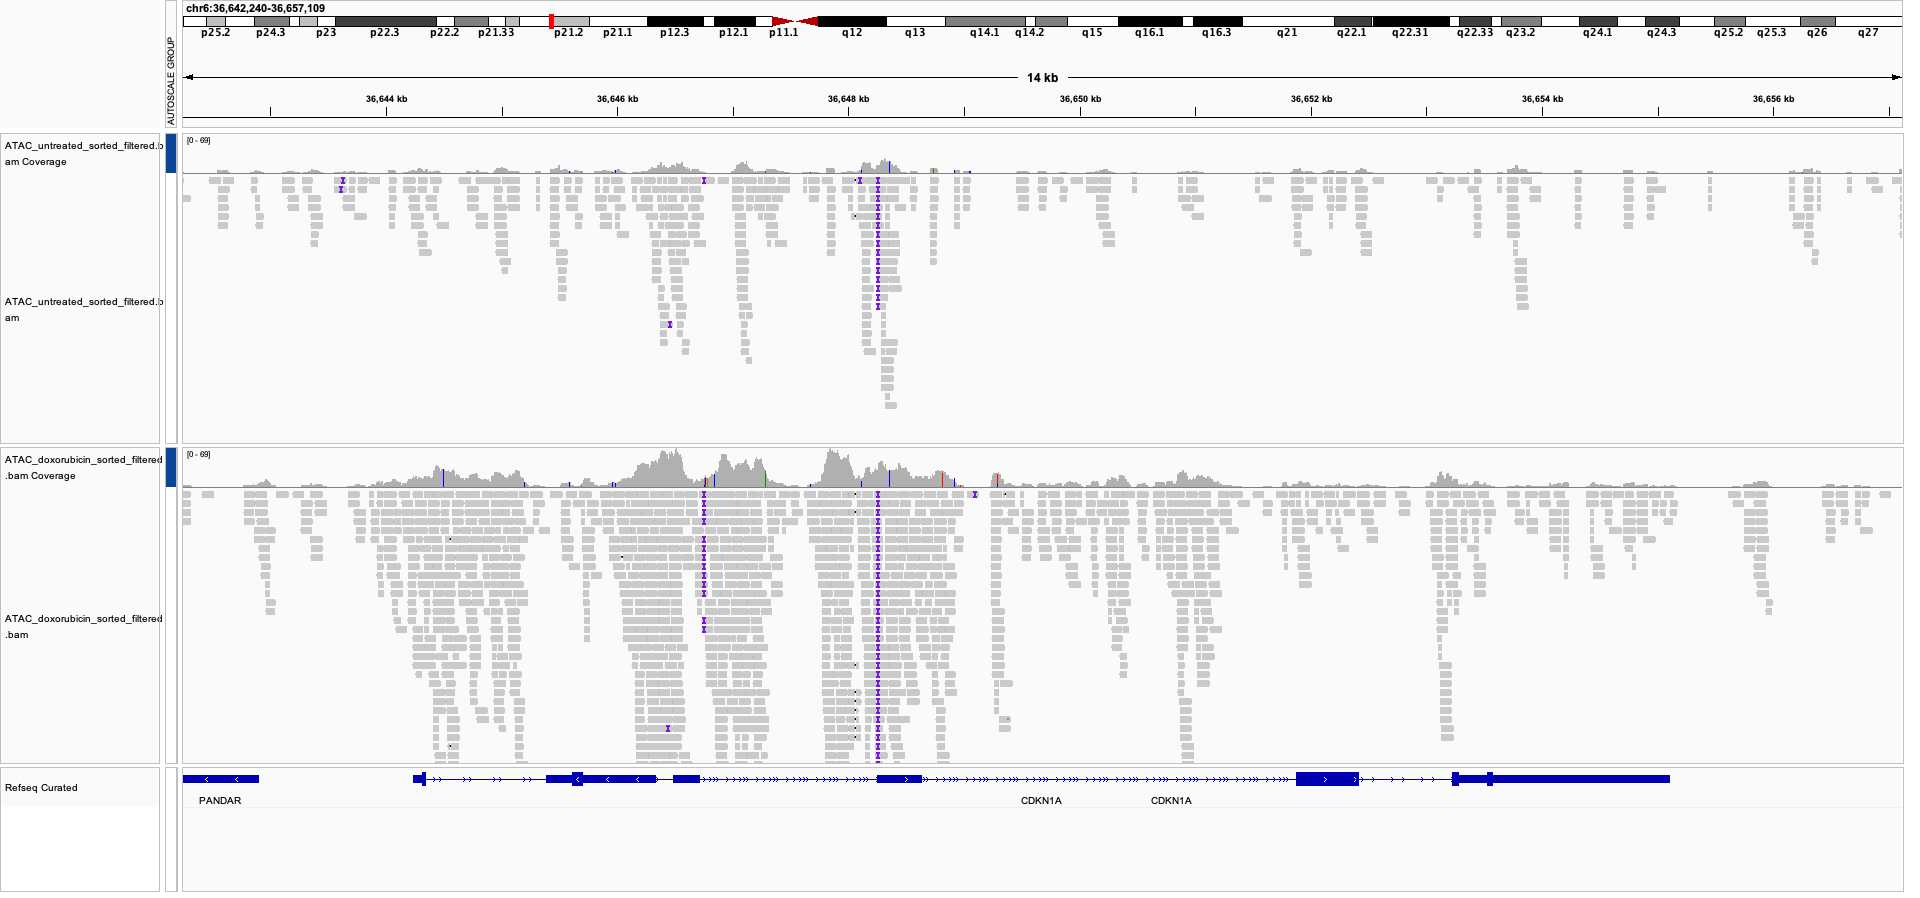

# Genome Coverage

Now we can also generate genome coverage files, they will look similiar to (but not identical) the coverage track we have in our bam files. This files are used to visualize your data in IGV or UCSC.

It's also a good exercise to generate the coverage files ourselves and compare it with the provided ones (if any). For that you can use the code below. Note that the first -bs argument (bin size) is quite high here so we will get a coarse looking coverage file. This is done here to decrease the compute time but it's usually a better idea to use a lower bin size in your own work (5 might be a good place to start).

BigWig coverage of untreated sample

In [50]:
bamCoverage -p 16 -b ATAC_untreated_sorted_filtered.bam --normalizeUsing RPGC --effectiveGenomeSize 2864785220 -o ATAC_untreated_hbs.bw -bs 50

normalization: 1x (effective genome size 2864785220)
bamFilesList: ['ATAC_untreated_sorted_filtered.bam']
binLength: 50
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 16
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 50
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


In [51]:
bamCoverage -p 16 -b ATAC_untreated_sorted_filtered.bam --normalizeUsing RPGC --effectiveGenomeSize 2864785220 -o ATAC_untreated_sbs.bw -bs 5

normalization: 1x (effective genome size 2864785220)
bamFilesList: ['ATAC_untreated_sorted_filtered.bam']
binLength: 5
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 16
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 5
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


BigWig coverage of doxorubicin sample

In [52]:
bamCoverage -p 16 -b ATAC_doxorubicin_sorted_filtered.bam --normalizeUsing RPGC --effectiveGenomeSize 2864785220 -o ATAC_doxorubicin_hbs.bw -bs 50

normalization: 1x (effective genome size 2864785220)
bamFilesList: ['ATAC_doxorubicin_sorted_filtered.bam']
binLength: 50
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 16
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 50
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


In [53]:
bamCoverage -p 16 -b ATAC_doxorubicin_sorted_filtered.bam --normalizeUsing RPGC --effectiveGenomeSize 2864785220 -o ATAC_doxorubicin_sbs.bw -bs 5

normalization: 1x (effective genome size 2864785220)
bamFilesList: ['ATAC_doxorubicin_sorted_filtered.bam']
binLength: 5
numberOfSamples: None
blackListFileName: None
skipZeroOverZero: False
bed_and_bin: False
genomeChunkSize: None
defaultFragmentLength: read length
numberOfProcessors: 16
verbose: False
region: None
bedFile: None
minMappingQuality: None
ignoreDuplicates: False
chrsToSkip: []
stepSize: 5
center_read: False
samFlag_include: None
samFlag_exclude: None
minFragmentLength: 0
maxFragmentLength: 0
zerosToNans: False
smoothLength: None
save_data: False
out_file_for_raw_data: None
maxPairedFragmentLength: 1000


Having generated the ATAC bigWig files, it's a good idea to also load the TF and H3K27Ac ChIP-seq coverage files that you have used before and observe how it differs from the ATAC-seq data:

BBC3 gene

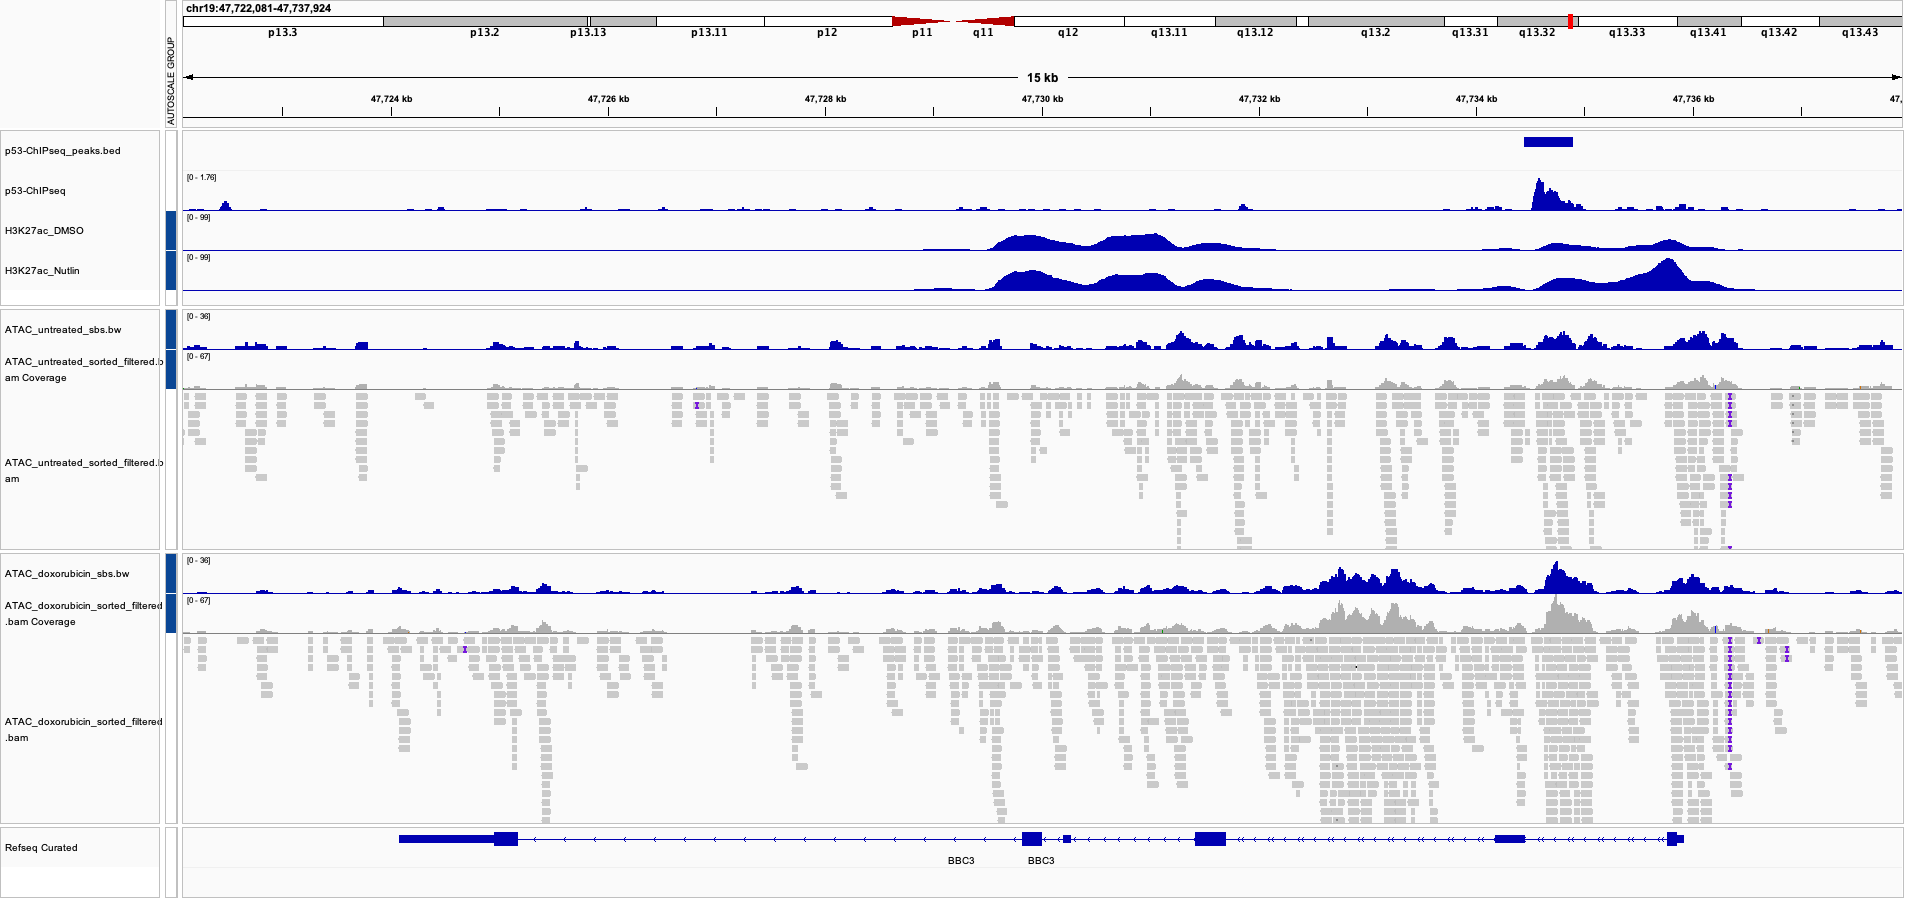

CDKN1A gene

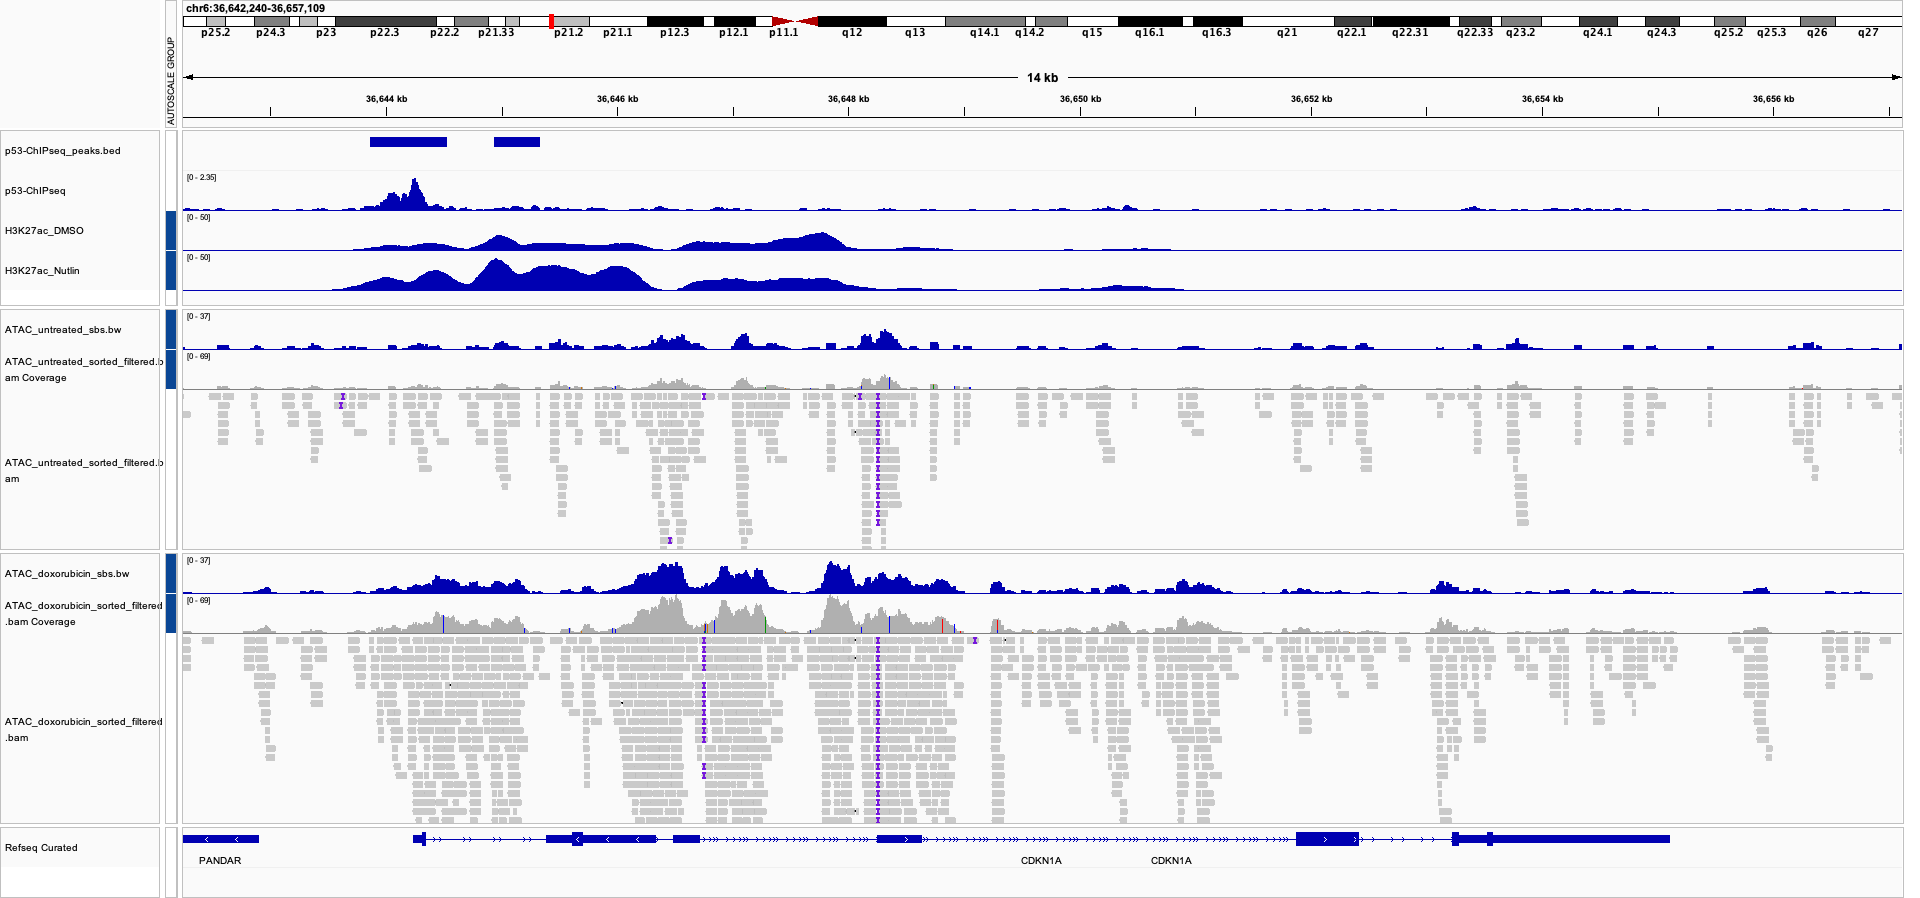

For example, the peak near the BBC3 gene shows a small increase in H3K27Ac between DMSO-treated and Nutlin-treated cells and a slightly bigger increase in the ATAC signal between Untreated and Doxorubicin-treated cells.

# Visualize ATAC-seq data on the TP53 ChIP-seq peaks

After creating the bigWig files, we can visualize their coverage on the previous p53 ChIP-seq peaks

In [54]:
ls -lt *.bw

-rw-r--r-- 1 u0160030 domain users 216592389 Oct 23 00:07 ATAC_doxorubicin_sbs.bw
-rw-r--r-- 1 u0160030 domain users 127230544 Oct 23 00:05 ATAC_doxorubicin_hbs.bw
-rw-r--r-- 1 u0160030 domain users 145222445 Oct 23 00:04 ATAC_untreated_sbs.bw
-rw-r--r-- 1 u0160030 domain users  99509411 Oct 23 00:03 ATAC_untreated_hbs.bw


Create a link to the p53_peaks.narrowPeak, which contains all p53 peaks (from the entire genome; we have created this using macs3 callpeak)

In [55]:
ln -sf /data/teachers/data/chip_seq/p53/p53-full_peaks.narrowPeak .

In [56]:
wc -l p53-full_peaks.narrowPeak

774 p53-full_peaks.narrowPeak


Create a BED file from the narrowpeak file:

In [57]:
cat p53-full_peaks.narrowPeak | cut -f 1-3 | head

chr1	5143953	5144175
chr1	8925385	8925583
chr1	9241987	9242471
chr1	12267171	12267437
chr1	12678434	12678631
chr1	23919129	23919326
chr1	24019022	24019268
chr1	24020186	24020406
chr1	24021048	24021266
chr1	35649920	35650151


In [58]:
cat p53-full_peaks.narrowPeak | cut -f 1-3 > p53-all_peaks.bed

We will use the deeptools commands to generate a heatmap, see here for more info: https://deeptools.readthedocs.io/en/develop/content/tools/plotHeatmap.html

In [59]:
computeMatrix scale-regions \
    -S ATAC_untreated_sbs.bw ATAC_doxorubicin_sbs.bw \
    -R p53-all_peaks.bed \
    -a 2000 \
    -b 2000 \
    -out p53-peaks-ATAC.tab.gz

In [60]:
plotHeatmap \
    -m p53-peaks-ATAC.tab.gz \
    -out p53-peaks-ATAC.png \
    --heatmapHeight 15 \
    --refPointLabel peak.center \
    --regionsLabel peaks \
    --samplesLabel ATAC_Untreated ATAC_Doxorubicin \
    --plotTitle 'ATAC-seq signal'

In [61]:
ls -lt *.png

-rw-r--r-- 1 u0160030 domain users 454867 Oct 23 00:26 p53-peaks-ATAC.png


We observe an increase in accessibility on the TP53 peaks, after treating with doxorubicin, indicating that these regions become active (because TP53 now binds there and activates target genes).

Note that many regions have no ATAC signal!

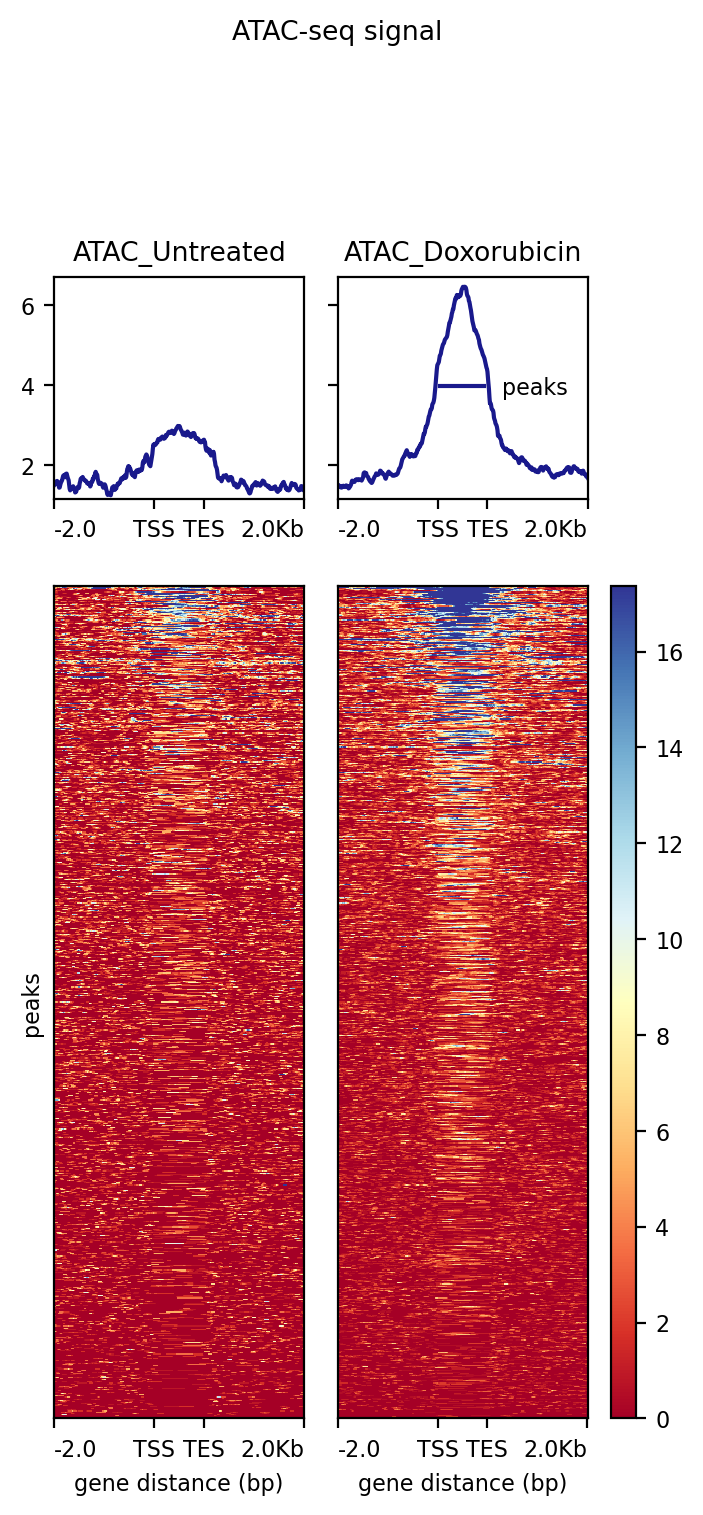
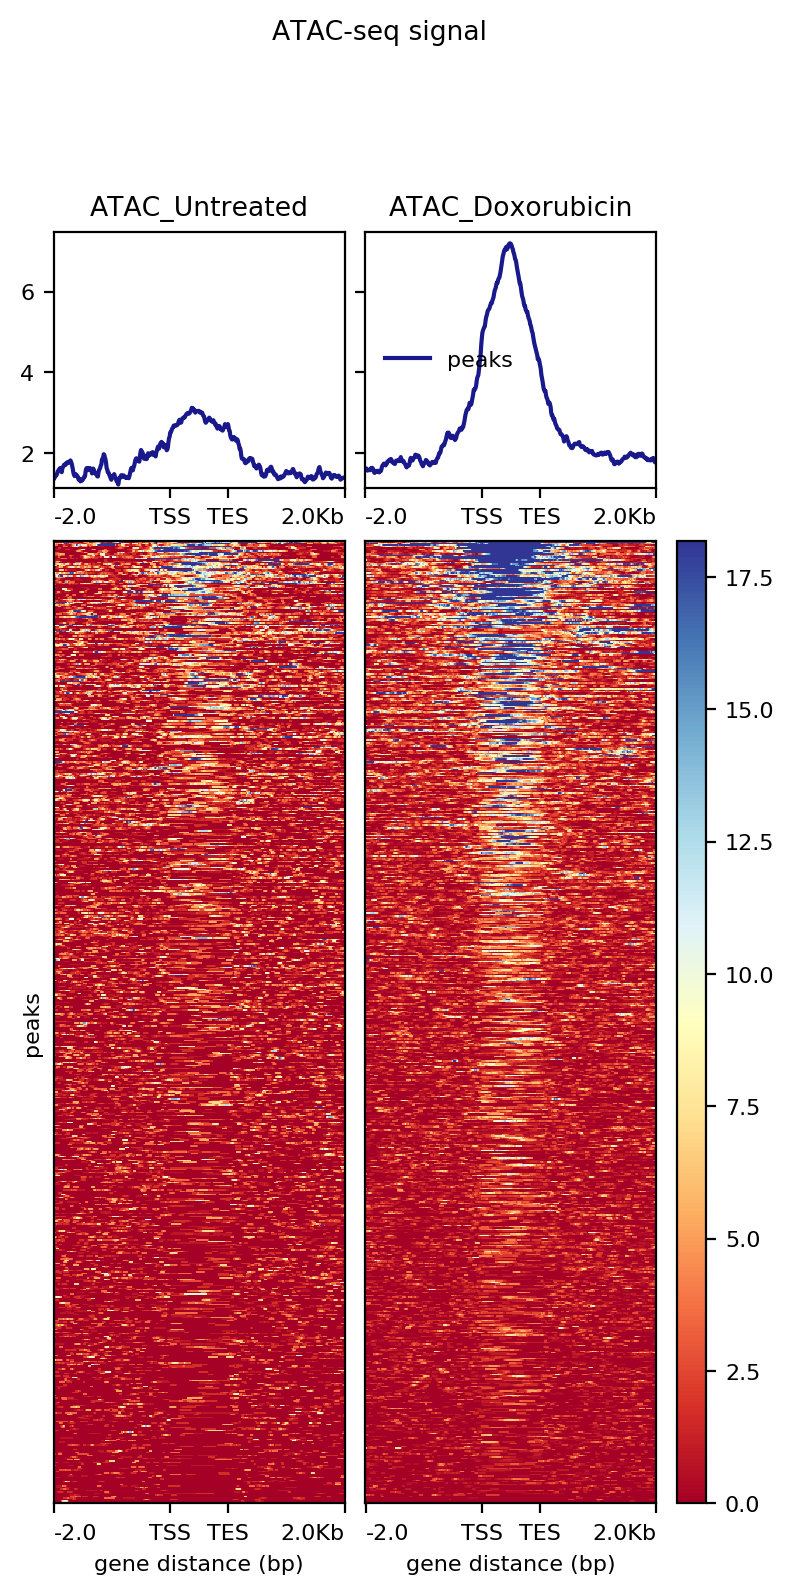

# Find differential ATAC-seq signal, genome-wide

Now we do peak calling per bam file, note that some arguments that we have used here are different that what you have seen before. This is due to our data being generated with a different method, ATAC-seq.

In [64]:
macs3 callpeak -B -t ATAC_untreated_sorted_filtered.bam -n untreated --nomodel --extsize 300

INFO  @ 23 Oct 2025 00:34:40: [32 MB] 
# Command line: callpeak -B -t ATAC_untreated_sorted_filtered.bam -n untreated --nomodel --extsize 300
# ARGUMENTS LIST:
# name = untreated
# format = AUTO
# ChIP-seq file = ['ATAC_untreated_sorted_filtered.bam']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 5.00e-02
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will be scaled towards smaller dataset.
# Range for calculating regional lambda is: 10000 bps
# Broad region calling is off
# Paired-End mode is off
 
INFO  @ 23 Oct 2025 00:34:40: [32 MB] #1 read tag files... 
INFO  @ 23 Oct 2025 00:34:40: [32 MB] #1 read treatment tags... 
INFO  @ 23 Oct 2025 00:34:40: [52 MB] Detected format is: BAM 
INFO  @ 23 Oct 2025 00:34:40: [52 MB] * Input file is gzipped. 
INFO  @ 23 Oct 2025 00:34:42: [60 MB]

In [65]:
macs3 callpeak -B -t ATAC_doxorubicin_sorted_filtered.bam -n doxorubicin --nomodel --extsize 300

INFO  @ 23 Oct 2025 00:36:11: [32 MB] 
# Command line: callpeak -B -t ATAC_doxorubicin_sorted_filtered.bam -n doxorubicin --nomodel --extsize 300
# ARGUMENTS LIST:
# name = doxorubicin
# format = AUTO
# ChIP-seq file = ['ATAC_doxorubicin_sorted_filtered.bam']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 5.00e-02
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will be scaled towards smaller dataset.
# Range for calculating regional lambda is: 10000 bps
# Broad region calling is off
# Paired-End mode is off
 
INFO  @ 23 Oct 2025 00:36:11: [32 MB] #1 read tag files... 
INFO  @ 23 Oct 2025 00:36:11: [32 MB] #1 read treatment tags... 
INFO  @ 23 Oct 2025 00:36:11: [52 MB] Detected format is: BAM 
INFO  @ 23 Oct 2025 00:36:11: [52 MB] * Input file is gzipped. 
INFO  @ 23 Oct 2025 00:36:14:

In [66]:
grep -E "tags after filtering in treatment|tags after filtering in control" doxorubicin_peaks.xls

# tags after filtering in treatment: 16324051


In [67]:
grep -E "tags after filtering in treatment|tags after filtering in control" untreated_peaks.xls

# tags after filtering in treatment: 10488636


In [69]:
ls -lt *.bdg

-rw-r--r-- 1 u0160030 domain users  609348510 Oct 23 00:38 doxorubicin_control_lambda.bdg
-rw-r--r-- 1 u0160030 domain users 1023434039 Oct 23 00:38 doxorubicin_treat_pileup.bdg
-rw-r--r-- 1 u0160030 domain users  401905860 Oct 23 00:36 untreated_control_lambda.bdg
-rw-r--r-- 1 u0160030 domain users  663550468 Oct 23 00:36 untreated_treat_pileup.bdg


In [70]:
macs3 bdgdiff \
    --t1 doxorubicin_treat_pileup.bdg \
    --c1 doxorubicin_control_lambda.bdg \
    --t2 untreated_treat_pileup.bdg \
    --c2 untreated_control_lambda.bdg \
    --d1 16324051 \
    --d2 10488636 \
    -g 60 \
    -l 120 \
    -C 3 \
    --o-prefix diff_doxorubicin_vs_untreated

INFO  @ 23 Oct 2025 00:43:41: [32 MB] Read and build treatment 1 bedGraph... 
INFO  @ 23 Oct 2025 00:43:54: [276 MB] Read and build control 1 bedGraph... 
INFO  @ 23 Oct 2025 00:44:02: [422 MB] Read and build treatment 2 bedGraph... 
INFO  @ 23 Oct 2025 00:44:10: [580 MB] Read and build control 2 bedGraph... 
INFO  @ 23 Oct 2025 00:45:15: [2031 MB] Write peaks... 
INFO  @ 23 Oct 2025 00:45:15: [2031 MB] Done 


In [71]:
ls -lt *.bed | head

-rw-r--r-- 1 u0160030 domain users 1539536 Oct 23 00:45 diff_doxorubicin_vs_untreated_c3.0_common.bed
-rw-r--r-- 1 u0160030 domain users  172355 Oct 23 00:45 diff_doxorubicin_vs_untreated_c3.0_cond2.bed
-rw-r--r-- 1 u0160030 domain users 1440736 Oct 23 00:45 diff_doxorubicin_vs_untreated_c3.0_cond1.bed
-rw-r--r-- 1 u0160030 domain users 3411018 Oct 23 00:38 doxorubicin_summits.bed
-rw-r--r-- 1 u0160030 domain users 1487846 Oct 23 00:36 untreated_summits.bed
-rw-r--r-- 1 u0160030 domain users   18453 Oct 23 00:26 p53-all_peaks.bed


In [72]:
wc -l *.bed

  21240 diff_doxorubicin_vs_untreated_c3.0_common.bed
  19686 diff_doxorubicin_vs_untreated_c3.0_cond1.bed
   2399 diff_doxorubicin_vs_untreated_c3.0_cond2.bed
  62380 doxorubicin_summits.bed
    774 p53-all_peaks.bed
  28351 untreated_summits.bed
 134830 total


Let's check the regions around some genes again. What do you notice? How does it compare to the TP53 ChIP-seq peaks and the H3K27ac differences between DMSO and Nutlin-treated cells?

BBC3 gene

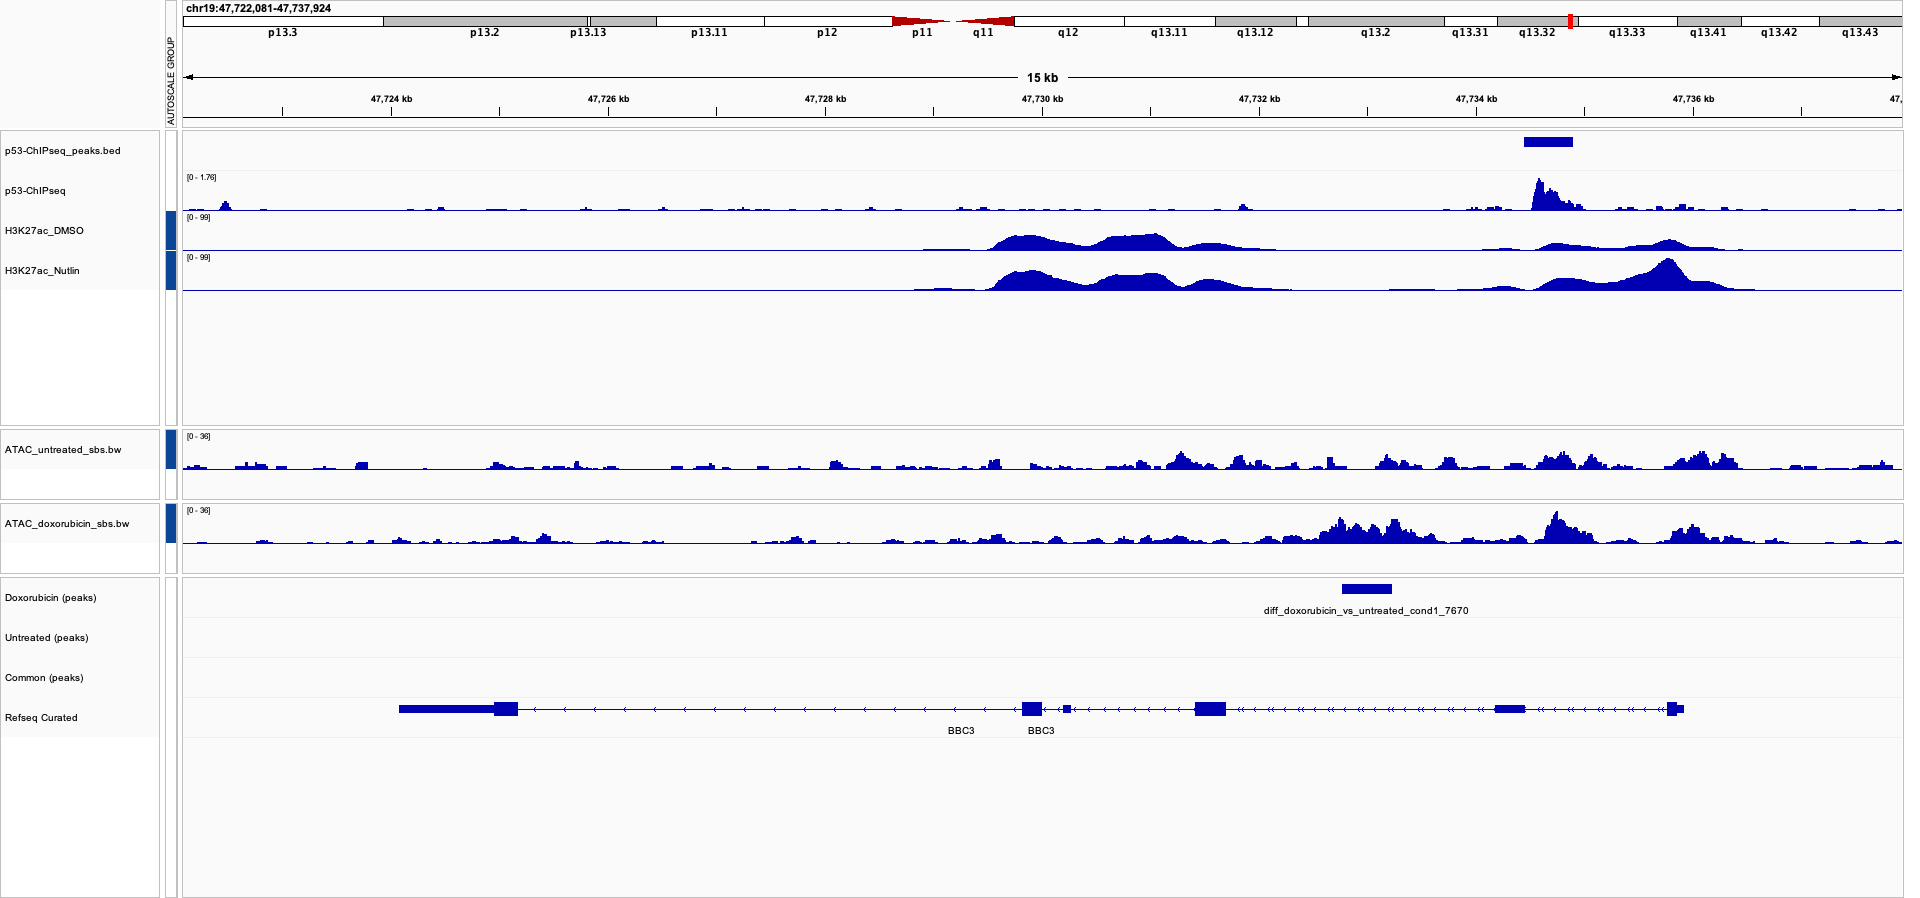

CDKN1A gene

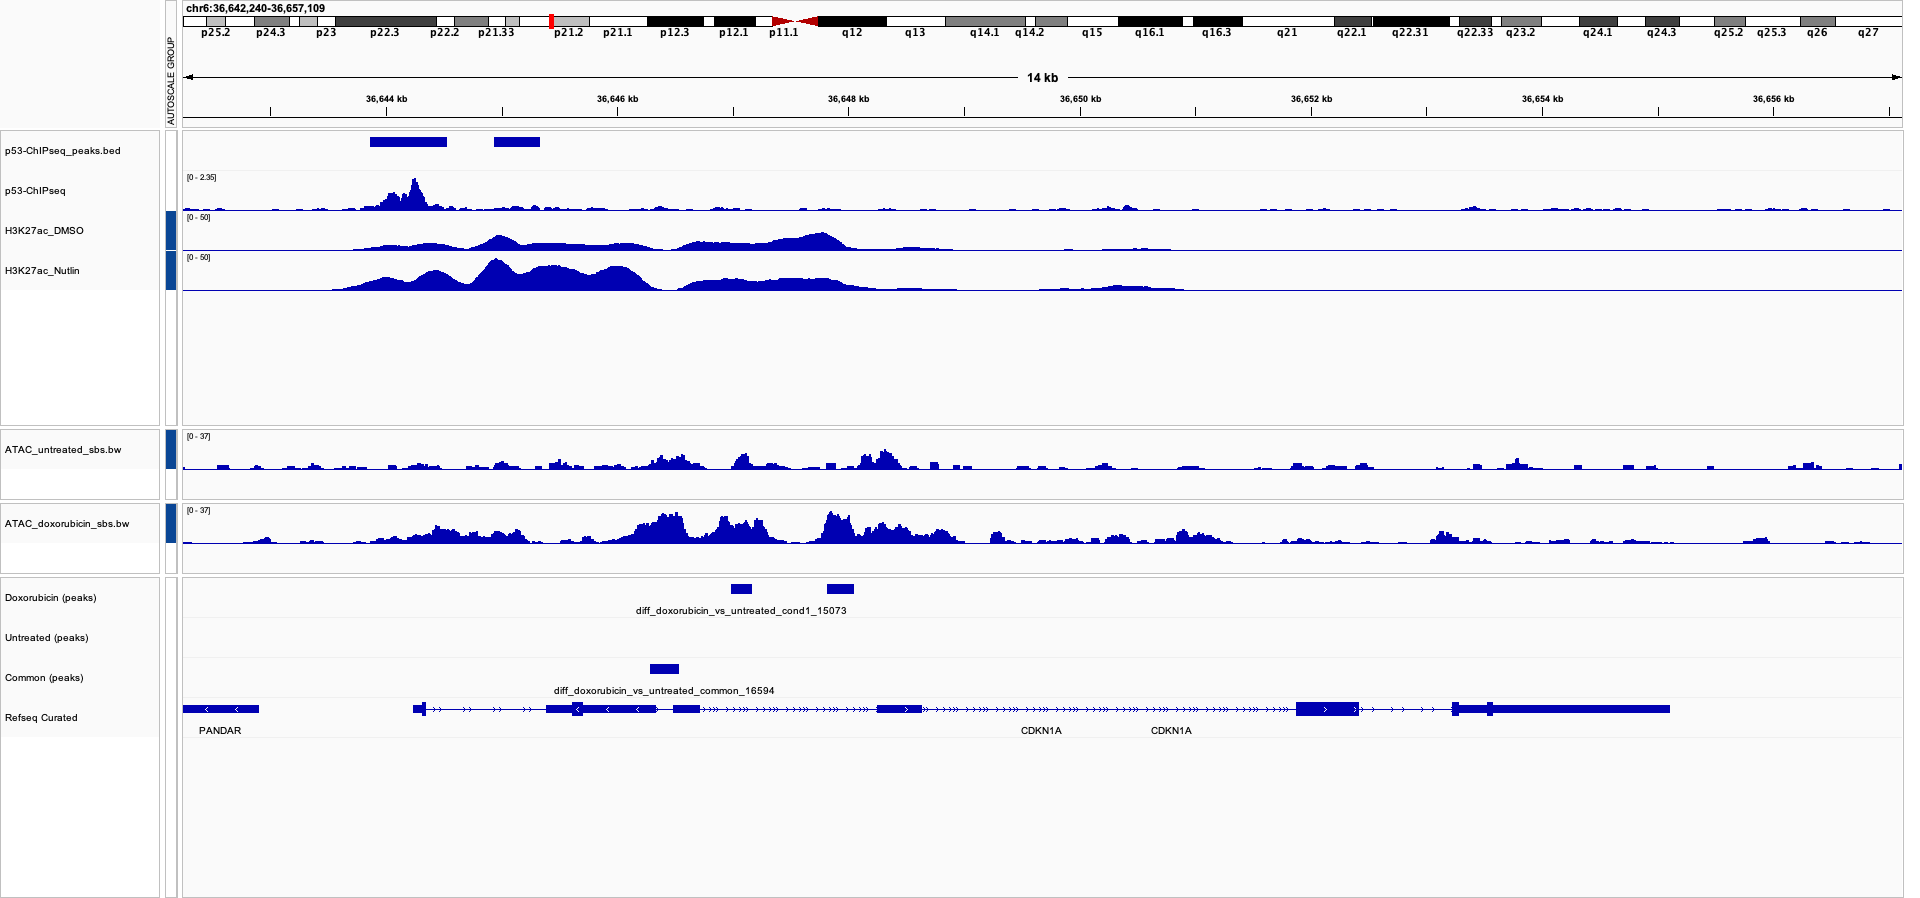

ABCA12 gene

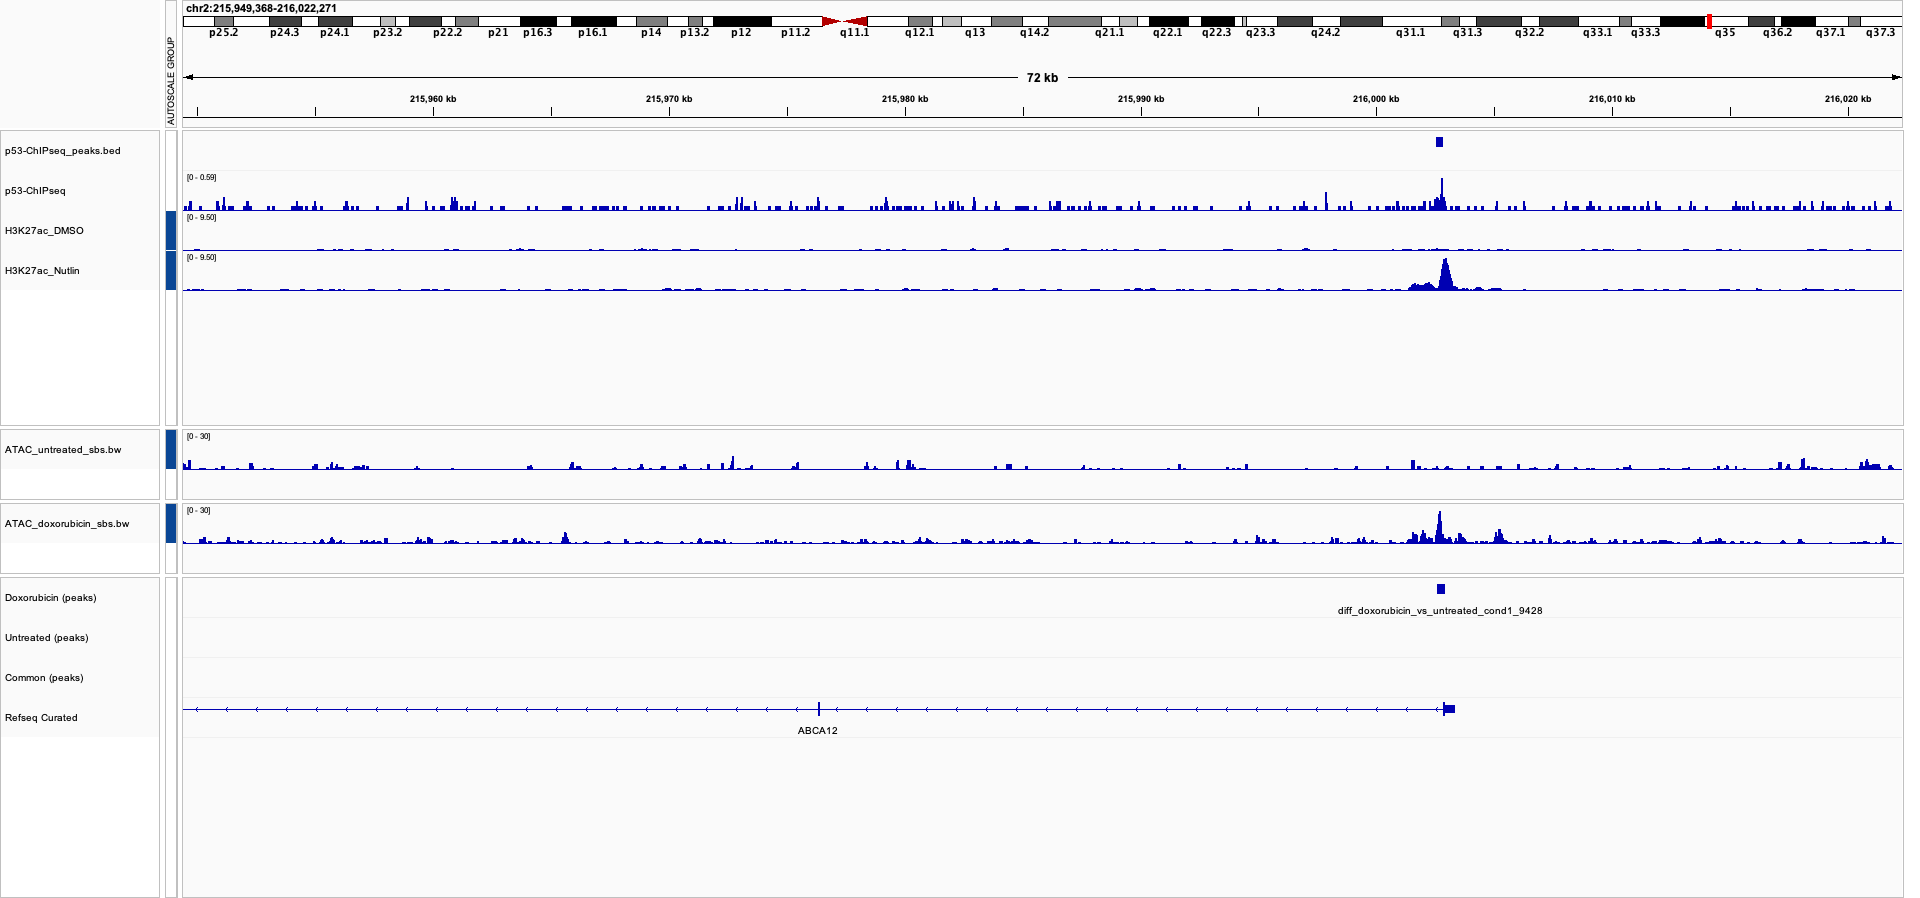

We can also get the topK regions to focus for other downstream analyses

In [73]:
cat diff_doxorubicin_vs_untreated_c3.0_cond1.bed | sort -k 5,5gr | head

chr12	117563080	117563676	diff_doxorubicin_vs_untreated_cond1_4495	74.0386
chr2	219710519	219711012	diff_doxorubicin_vs_untreated_cond1_9531	70.9757
chr4	186748994	186749796	diff_doxorubicin_vs_untreated_cond1_13394	64.3105
chr12	100689230	100689853	diff_doxorubicin_vs_untreated_cond1_4360	62.7065
chr16	58430789	58431606	diff_doxorubicin_vs_untreated_cond1_6536	62.3121
chr4	110518898	110519899	diff_doxorubicin_vs_untreated_cond1_12692	62.2667
chr5	126064636	126065171	diff_doxorubicin_vs_untreated_cond1_14332	61.4561
chr7	23675502	23676064	diff_doxorubicin_vs_untreated_cond1_16510	60.3648
chr10	5413221	5413858	diff_doxorubicin_vs_untreated_cond1_1851	59.6829
chr9	92295542	92296249	diff_doxorubicin_vs_untreated_cond1_18831	57.7372


In [74]:
cat diff_doxorubicin_vs_untreated_c3.0_cond1.bed | sort -k 5,5gr | head -n 1000 > diff_doxorubicin_vs_untreated_c3.0_cond1_top1k.bed
cat diff_doxorubicin_vs_untreated_c3.0_cond1.bed | sort -k 5,5gr | head -n 2000 > diff_doxorubicin_vs_untreated_c3.0_cond1_top2k.bed
cat diff_doxorubicin_vs_untreated_c3.0_cond1.bed | sort -k 5,5gr | head -n 5000 > diff_doxorubicin_vs_untreated_c3.0_cond1_top5k.bed

In [75]:
wc -l diff_doxorubicin_vs_untreated_c3.0_cond1_top1k.bed
wc -l diff_doxorubicin_vs_untreated_c3.0_cond1_top2k.bed
wc -l diff_doxorubicin_vs_untreated_c3.0_cond1_top5k.bed

1000 diff_doxorubicin_vs_untreated_c3.0_cond1_top1k.bed
2000 diff_doxorubicin_vs_untreated_c3.0_cond1_top2k.bed
5000 diff_doxorubicin_vs_untreated_c3.0_cond1_top5k.bed


Finally, we can also intersect the differentially accessible regions with the TP53 ChIP-seq peaks, so getting p53 binding sites that become more accessible.

In [76]:
bedtools intersect -a diff_doxorubicin_vs_untreated_c3.0_cond1.bed -b p53-all_peaks.bed > overlap_regions.bed

In [77]:
wc -l overlap_regions.bed

101 overlap_regions.bed


In [78]:
cat overlap_regions.bed | sort -k 5,5gr | head

chr5	27472067	27472513	diff_doxorubicin_vs_untreated_cond1_13535	37.0722
chr20	10713880	10714104	diff_doxorubicin_vs_untreated_cond1_9838	28.3304
chr7	137849590	137849802	diff_doxorubicin_vs_untreated_cond1_17287	22.0331
chr5	163546976	163547231	diff_doxorubicin_vs_untreated_cond1_14702	22
chr12	90628290	90628630	diff_doxorubicin_vs_untreated_cond1_4254	21.6971
chr3	13567778	13567912	diff_doxorubicin_vs_untreated_cond1_10386	21.0576
chr7	117270633	117270909	diff_doxorubicin_vs_untreated_cond1_17149	20.918
chr10	90750758	90751286	diff_doxorubicin_vs_untreated_cond1_2323	19.3732
chr4	108300750	108300868	diff_doxorubicin_vs_untreated_cond1_12653	18.7677
chr11	60331108	60331292	diff_doxorubicin_vs_untreated_cond1_3030	18.4971


Let's take a look at a couple of those:



PURPL (p53 upregulated regulator of p53 levels)

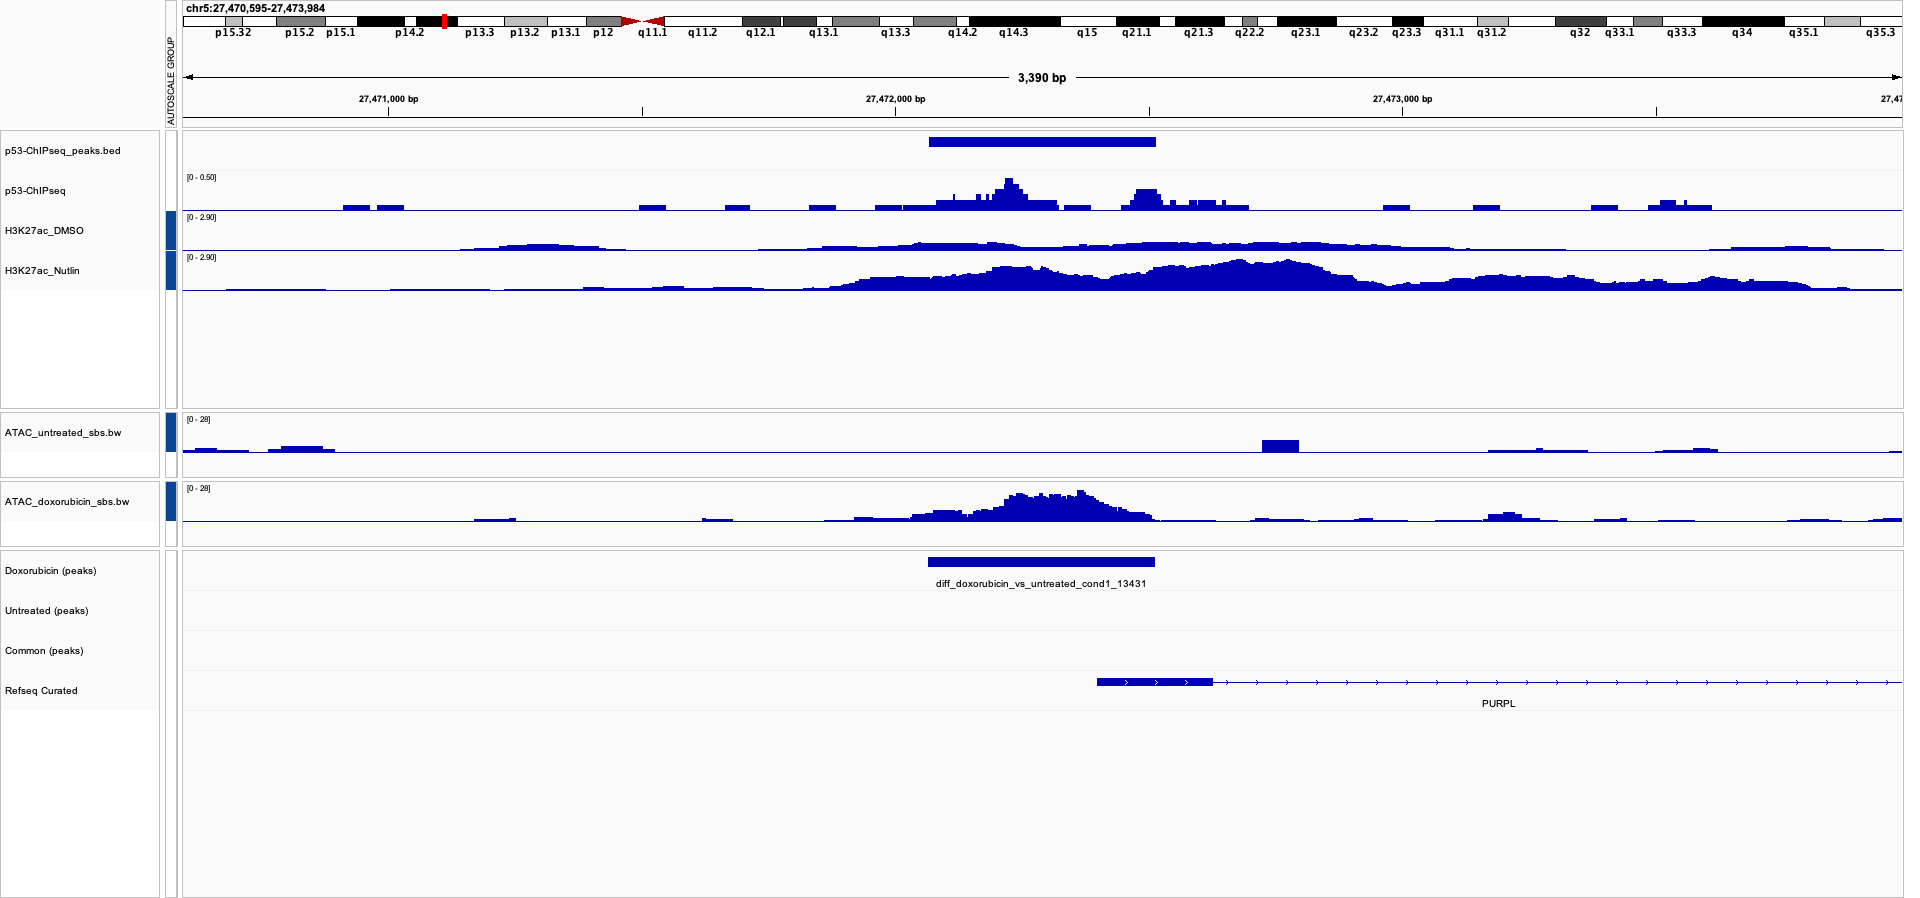

ACTA2

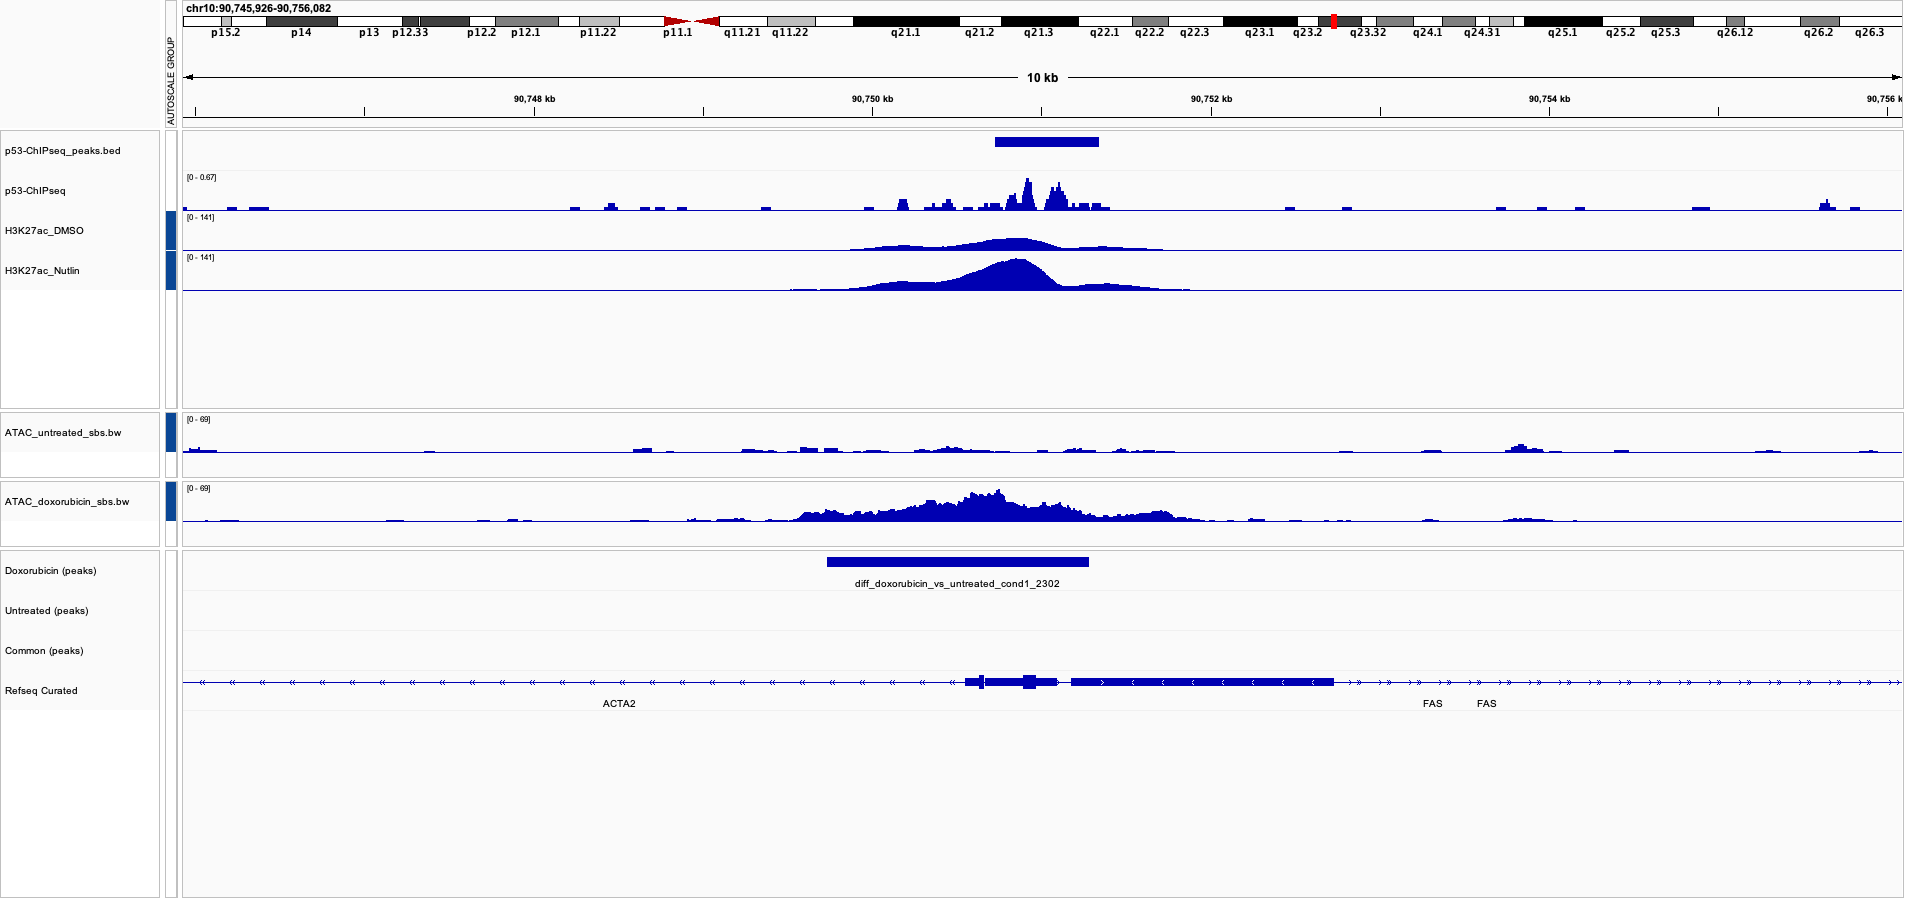

PTP4A1

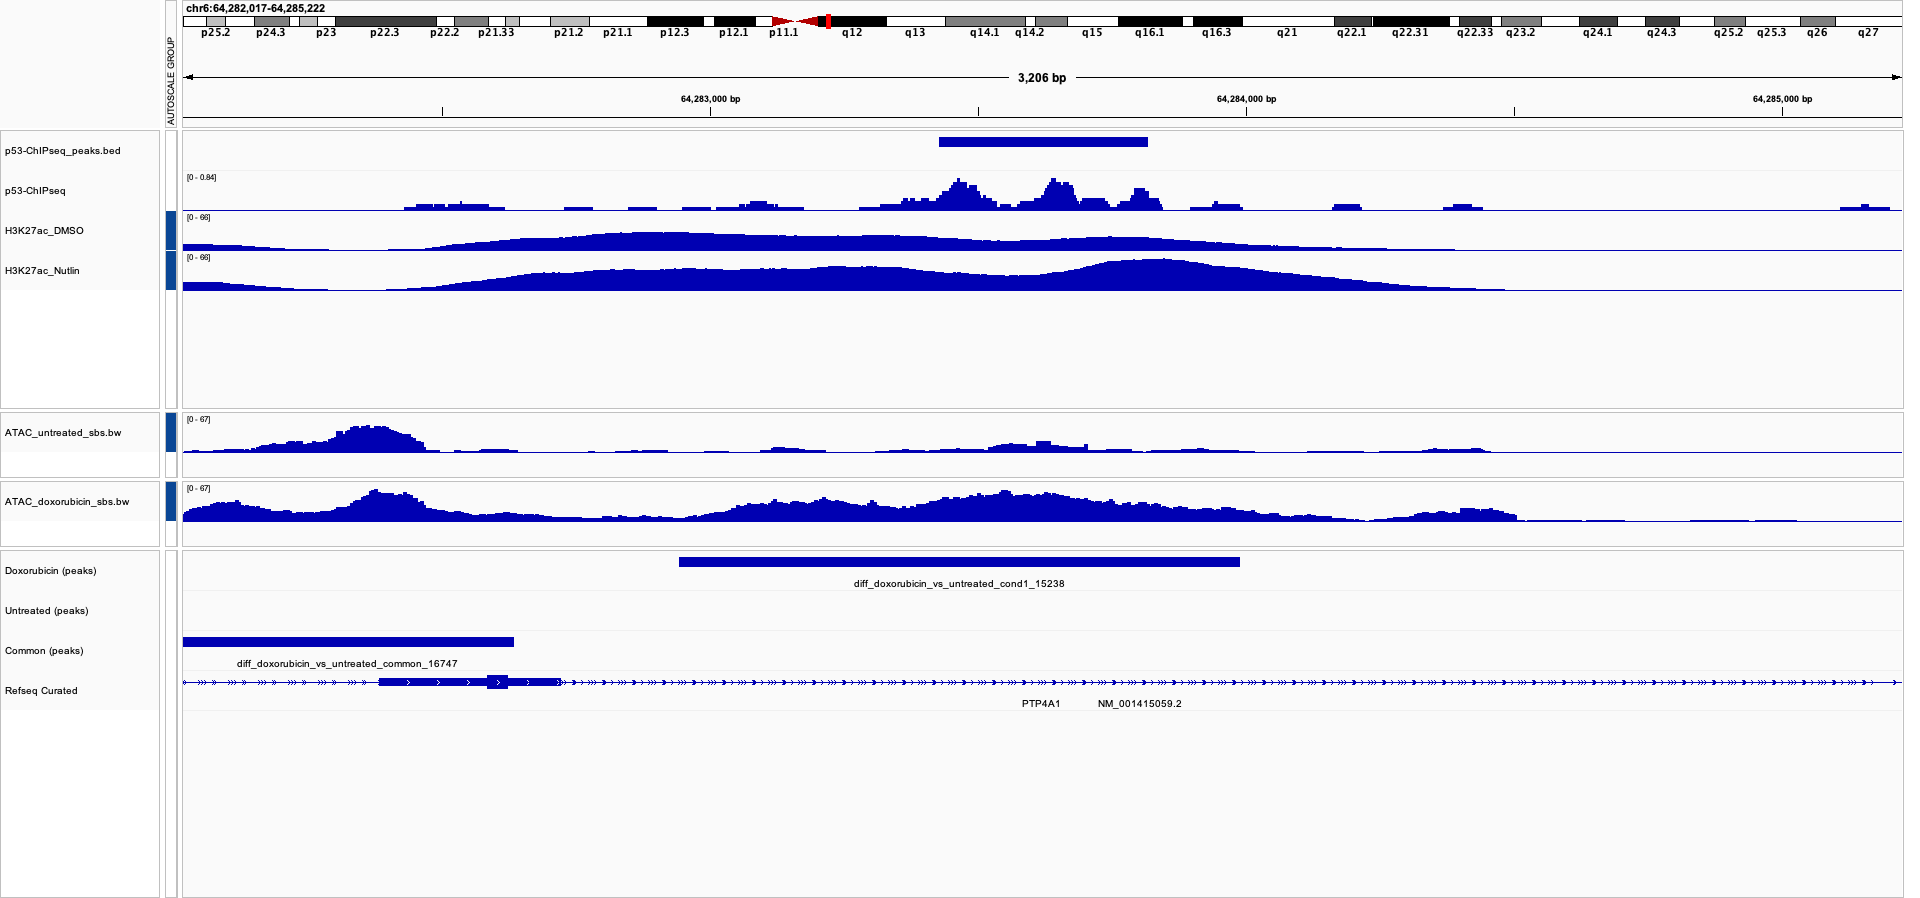

So from these plots and assays, you get different ways/angles to see what's happening after p53 stimulation and DNA damage and which genes p53 might target to propagate signals related to cell cycle arrest, apoptosis, etc.

Finally, you can continue with additional functional/motif analysis (e.g., using peaks, overlap regions, etc) as we will see in another notebook.